In [1]:
import time

import pandas as pd
import numpy as np

import matplotlib.pyplot as plot
import seaborn as sns

from scipy.special import expit, logit
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

import mlflow
import mlflow.sklearn
from mlflow.models.signature import infer_signature
import optuna
import shap

## Load Data

In [2]:
df = pd.read_csv("../data/Base.csv")

## Initial Inspection

In [4]:
df.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


In [5]:
df.isna().sum()

fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

In [6]:
df.describe(include="all")

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.0,1000000.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,NaN,7,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,5,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AB,NaN,NaN,NaN,NaN,NaN,NaN,CA,NaN,NaN,BC,NaN,NaN,NaN,NaN,NaN,NaN,INTERNET,NaN,other,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,370554,NaN,NaN,NaN,NaN,NaN,NaN,730252,NaN,NaN,372143,NaN,NaN,NaN,NaN,NaN,NaN,992952,NaN,342728,NaN,NaN,NaN,NaN
mean,0.011029,0.562696,0.493694,16.718568,86.587867,33.689080,1.025705e+00,8.661499,NaN,1572.692049,5665.296605,4769.781965,4856.324016,184.361849,9.503544,NaN,130.989595,0.529886,NaN,0.417077,0.889676,10.839303,0.222988,515.851010,0.025242,NaN,7.544940,NaN,0.576947,1.018312,0.0,3.288674
std,0.104438,0.290343,0.289125,44.046230,88.406599,12.025799,5.381835e+00,20.236155,NaN,1005.374565,3009.380665,1479.212612,919.843934,459.625329,5.033792,NaN,69.681812,0.499106,NaN,0.493076,0.313293,12.116875,0.416251,487.559902,0.156859,NaN,8.033106,NaN,0.494044,0.180761,0.0,2.209994
min,0.000000,0.100000,0.000001,-1.000000,-1.000000,10.000000,4.036860e-09,-15.530555,NaN,1.000000,-170.603072,1300.307314,2825.748405,0.000000,0.000000,NaN,-170.000000,0.000000,NaN,0.000000,0.000000,-1.000000,0.000000,190.000000,0.000000,NaN,-1.000000,NaN,0.000000,-1.000000,0.0,0.000000
25%,0.000000,0.300000,0.225216,-1.000000,19.000000,20.000000,7.193246e-03,-1.181488,NaN,894.000000,3436.365848,3593.179135,4268.368423,1.000000,6.000000,NaN,83.000000,0.000000,NaN,0.000000,1.000000,-1.000000,0.000000,200.000000,0.000000,NaN,3.103053,NaN,0.000000,1.000000,0.0,1.000000
50%,0.000000,0.600000,0.492153,-1.000000,52.000000,30.000000,1.517574e-02,-0.830507,NaN,1263.000000,5319.769349,4749.921161,4913.436941,9.000000,9.000000,NaN,122.000000,1.000000,NaN,0.000000,1.000000,5.000000,0.000000,200.000000,0.000000,NaN,5.114321,NaN,1.000000,1.000000,0.0,3.000000
75%,0.000000,0.800000,0.755567,12.000000,130.000000,40.000000,2.633069e-02,4.984176,NaN,1944.000000,7680.717827,5752.574191,5488.083356,25.000000,13.000000,NaN,178.000000,1.000000,NaN,1.000000,1.000000,25.000000,0.000000,500.000000,0.000000,NaN,8.866131,NaN,1.000000,1.000000,0.0,5.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000

## Preprocessing

Negative values in these columns are missing data, they are flagged and replaced with NaNs. Non-feature columns are kept at this staged and removed later after visualisation.

Missingness indicators are also added as this carries information if it's systematic.

In [8]:
missing_coded_cols = [
    'intended_balcon_amount',
    'prev_address_months_count',
    'bank_months_count',
    'current_address_months_count',
    'session_length_in_minutes',
    'device_distinct_emails_8w'
]

for col in missing_coded_cols:
    df[f'{col}_missing_flag'] = (df[col] < 0).astype(int)
    df.loc[df[col] < 0, col] = np.nan

df[missing_coded_cols + [f'{col}_missing_flag' for col in missing_coded_cols]].head()


,intended_balcon_amount,prev_address_months_count,bank_months_count,current_address_months_count,session_length_in_minutes,device_distinct_emails_8w,intended_balcon_amount_missing_flag,prev_address_months_count_missing_flag,bank_months_count_missing_flag,current_address_months_count_missing_flag,session_length_in_minutes_missing_flag,device_distinct_emails_8w_missing_flag
0,102.453711,NaN,9.0,25.0,16.224843,1.0,0,1,0,0,0,0
1,NaN,NaN,2.0,89.0,3.363854,1.0,1,1,0,0,0,0
2,NaN,9.0,30.0,14.0,22.730559,1.0,1,0,0,0,0,0
3,NaN,11.0,1.0,14.0,15.215816,1.0,1,0,0,0,0,0
4,47.152498,NaN,26.0,29.0,3.743048,1.0,0,1,0,0,0,0


In [9]:
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
df[categorical_cols] = df[categorical_cols].astype('category')

df.dtypes

fraud_bool                                      int64
income                                        float64
name_email_similarity                         float64
prev_address_months_count                     float64
current_address_months_count                  float64
customer_age                                    int64
days_since_request                            float64
intended_balcon_amount                        float64
payment_type                                 category
zip_count_4w                                    int64
velocity_6h                                   float64
velocity_24h                                  float64
velocity_4w                                   float64
bank_branch_count_8w                            int64
date_of_birth_distinct_emails_4w                int64
employment_status                            category
credit_risk_score                               int64
email_is_free                                   int64
housing_status              

## Feature Types

In [10]:
target = "fraud_bool"

continuous_vars = df.select_dtypes(include="float64").columns.tolist()
discrete_vars = [c for c in df.select_dtypes(include="int64").columns if c != target]
categorical_vars = df.select_dtypes(include='category').columns.tolist()

print(f"Continuous variables ({len(continuous_vars)}):")
print(continuous_vars)

print(f"\nDiscrete variables ({len(discrete_vars)}):")
print(discrete_vars)

print(f"\nCategorical variables ({len(categorical_vars)}):")
print(categorical_vars)


Continuous variables (13):
['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'days_since_request', 'intended_balcon_amount', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_months_count', 'proposed_credit_limit', 'session_length_in_minutes', 'device_distinct_emails_8w']

Discrete variables (19):
['customer_age', 'zip_count_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'credit_risk_score', 'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'has_other_cards', 'foreign_request', 'keep_alive_session', 'device_fraud_count', 'month', 'intended_balcon_amount_missing_flag', 'prev_address_months_count_missing_flag', 'bank_months_count_missing_flag', 'current_address_months_count_missing_flag', 'session_length_in_minutes_missing_flag', 'device_distinct_emails_8w_missing_flag']

Categorical variables (5):
['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']


## Fraud Rate by Month

`month` is a temporal column rather than a feature and is used to split into training and test sets. Visualised below is the change in fraud cases per month.

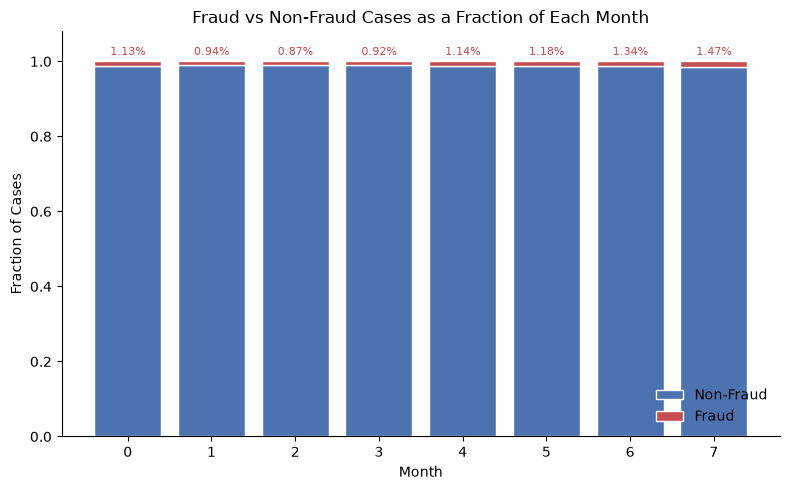

In [11]:
month_fraud = df.groupby('month')['fraud_bool'].value_counts(normalize=True).unstack()[[0, 1]]
month_fraud.columns = ['Non-Fraud', 'Fraud']

fig, ax = plot.subplots(figsize=(8, 5))

bars_nonfraud = ax.bar(
    month_fraud.index, month_fraud['Non-Fraud'],
    color='#4C72B0', edgecolor='white', linewidth=1, label='Non-Fraud'
)
bars_fraud = ax.bar(
    month_fraud.index, month_fraud['Fraud'], bottom=month_fraud['Non-Fraud'],
    color='#C44E52', edgecolor='white', linewidth=1, label='Fraud'
)

for month, frac in month_fraud['Fraud'].items():
    ax.text(month, 1.01, f'{frac:.2%}', ha='center', va='bottom', fontsize=8, color='#C44E52')

ax.set_xlabel('Month')
ax.set_ylabel('Fraction of Cases')
ax.set_title('Fraud vs Non-Fraud Cases as a Fraction of Each Month')
ax.set_xticks(month_fraud.index)
ax.set_ylim(0, 1.08)
ax.legend(loc='lower right', frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plot.tight_layout()
plot.show()

## Train Test Split

Each month has approximately 125k rows. The split train test split is 7:1

In [12]:
train_months = [0, 1, 2, 3, 4, 5, 6]
val_months = [7]

train_df = df[df["month"].isin(train_months)]
val_df = df[df["month"].isin(val_months)]

X_train = train_df.drop(columns=["month", target])
y_train = train_df[target]

X_val = val_df.drop(columns=["month", target])
y_val = val_df[target]

In [13]:
print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(y_val.shape)

(903157, 36)
(903157,)
(96843, 36)
(96843,)


## Feature Distributions

Each feature's distribution is compared between fraud and non-fraud on the training months. Both classes are normalized (density / share within class), so the ~1% fraud class is visible on the same scale.

In [ ]:
CLASS_COLORS = {0: '#2a78d6', 1: '#eb6834'}
CLASS_LABELS = {0: 'Non-Fraud', 1: 'Fraud'}
MAX_BAR_LEVELS = 12  # numeric features with this many distinct values or fewer get bar charts

eda_df = train_df.drop(columns=['month'])


def style_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=10, loc='left')
    ax.set_ylabel(ylabel, fontsize=8, color='#52514e')
    ax.tick_params(labelsize=8, colors='#52514e')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
    ax.set_axisbelow(True)


def plot_histogram(ax, col, bins=40):
    values = eda_df[col].dropna()

    # Heavily right-skewed features are shown on a log10 scale so the bulk isn't one spike at zero
    shift = None
    if values.min() >= 0 and values.skew() > 2.5:
        shift = 0 if values.min() > 0 else 1
        values = np.log10(values + shift)

    # Trim the extreme 0.5% tails so outliers don't squash the rest of the distribution
    lo, hi = values.quantile([0.005, 0.995])
    if shift is None and (values % 1 == 0).all():
        # Integer-valued: align bins to whole numbers to avoid empty-bin comb artifacts
        step = max(1, int(np.ceil((hi - lo) / bins)))
        edges = np.arange(lo - 0.5, hi + step, step)
    else:
        edges = np.linspace(lo, hi, bins + 1)

    for cls in (0, 1):
        data = values[eda_df.loc[values.index, target] == cls]
        ax.hist(data[data.between(lo, hi)], bins=edges, density=True, histtype='step',
                linewidth=2, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls])

    if shift is None:
        title = col
    elif shift == 0:
        title = f'log10({col})'
    else:
        title = f'log10(1 + {col})'
    style_axis(ax, title, 'Density')


def plot_bar_shares(ax, col):
    shares = (eda_df.groupby(target, observed=True)[col]
              .value_counts(normalize=True)
              .unstack(target)
              .fillna(0)
              .sort_index())
    x = np.arange(len(shares))
    width = 0.4
    for cls in (0, 1):
        # Non-fraud bars sit just left of each tick, fraud bars just right
        offset = (cls - 0.5) * width
        ax.bar(x + offset, shares[cls], width=width, color=CLASS_COLORS[cls],
               edgecolor='white', linewidth=2, label=CLASS_LABELS[cls])

    labels = []
    for level in shares.index:
        if isinstance(level, (int, float, np.number)):
            labels.append(f'{level:g}')
        else:
            labels.append(str(level))
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45 if len(labels) > 6 else 0)
    style_axis(ax, col, 'Share within class')


def plot_feature_grid(cols, title, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plot.subplots(nrows, ncols, figsize=(max(4 * ncols, 10), 3 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, cols):
        if col in categorical_vars or eda_df[col].nunique() <= MAX_BAR_LEVELS:
            plot_bar_shares(ax, col)
        else:
            plot_histogram(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', ncol=2, frameon=False)
    fig.suptitle(title, x=0.01, ha='left', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plot.show()


def plot_fraud_rate(ax, col, data=None):
    data = eda_df if data is None else data
    rates = data.groupby(col, observed=True)[target].agg(['mean', 'size'])
    base_rate = data[target].mean() * 100
    x = np.arange(len(rates))
    ax.bar(x, rates['mean'] * 100, width=0.6, color=CLASS_COLORS[1], edgecolor='white', linewidth=2)
    ax.axhline(base_rate, color='#52514e', linestyle='--', linewidth=1)

    # Labels sit above both the bar and the base-rate line so they don't collide
    for xi, rate, n in zip(x, rates['mean'], rates['size']):
        ax.text(xi, max(rate * 100, base_rate) * 1.04, f'{rate:.2%}\nn={n:,}',
                ha='center', va='bottom', fontsize=8, color='#52514e')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{v:g}' for v in rates.index])
    ax.set_ylim(0, max(rates['mean'].max() * 100, base_rate) * 1.5)
    style_axis(ax, col, 'Fraud rate (%)')

### Columns to Remove

- `month` is already excluded from `X_train` / `X_val` by the split above.
- `device_fraud_count` is a constant 0 for each row so it carries no information.
- `session_length_in_minutes_missing_flag` and `device_distinct_emails_8w_missing_flag` cover very few rows and their fraud rates sit close to the base rate.

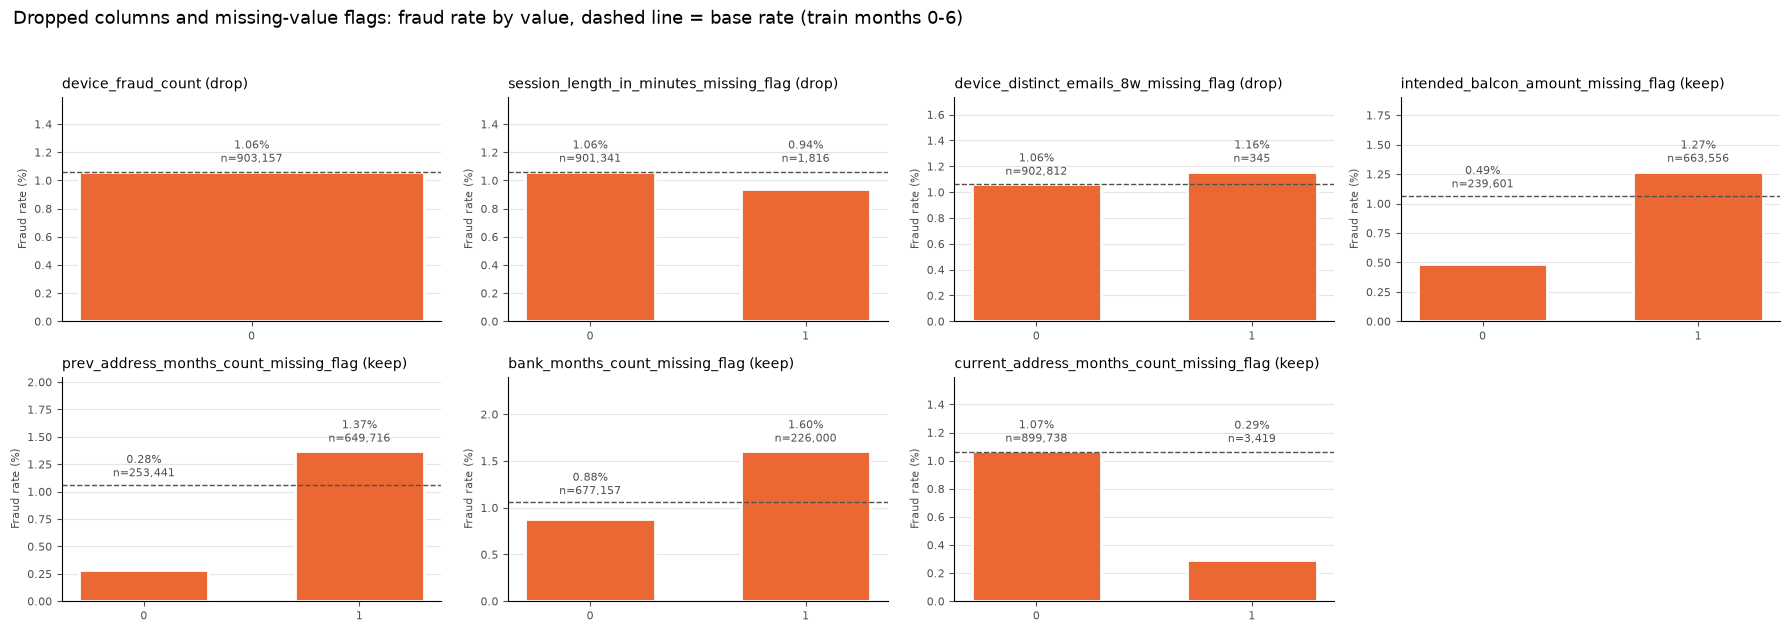

Base fraud rate (train): 1.06%


rows  fraud_rate_%
feature                                   value                      
device_fraud_count                        0      903157          1.06
session_length_in_minutes_missing_flag    0      901341          1.06
                                          1        1816          0.94
device_distinct_emails_8w_missing_flag    0      902812          1.06
                                          1         345          1.16
intended_balcon_amount_missing_flag       0      239601          0.49
                                          1      663556          1.27
prev_address_months_count_missing_flag    0      253441          0.28
                                          1      649716          1.37
bank_months_count_missing_flag            0      677157          0.88
                                          1      226000          1.60
current_address_months_count_missing_flag 0      899738          1.07
                                          1        3419          0.29

In [15]:
cols_to_drop = [
    'device_fraud_count',
    'session_length_in_minutes_missing_flag',
    'device_distinct_emails_8w_missing_flag',
]

# Plot every missing-value flag alongside the dropped columns, so the kept flags can be compared with the dropped ones
flag_cols = [col for col in eda_df.columns if col.endswith('_flag')]
plot_cols = cols_to_drop + [col for col in flag_cols if col not in cols_to_drop]

n_cols = 4
n_rows = int(np.ceil(len(plot_cols) / n_cols))
fig, axes = plot.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.2 * n_rows), squeeze=False)
for ax, col in zip(axes.flat, plot_cols):
    decision = 'drop' if col in cols_to_drop else 'keep'
    plot_fraud_rate(ax, col)
    ax.set_title(f'{col} ({decision})', fontsize=10, loc='left')
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
fig.suptitle('Dropped columns and missing-value flags: fraud rate by value, dashed line = base rate (train months 0-6)',
             x=0.01, ha='left', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plot.show()

print(f"Base fraud rate (train): {train_df[target].mean():.2%}")
fraud_rate_by_value = {
    col: train_df.groupby(col)[target].agg(rows='size', fraud_rate='mean')
    for col in plot_cols
}
drop_summary = pd.concat(fraud_rate_by_value, names=['feature', 'value'])
drop_summary['fraud_rate'] = (drop_summary['fraud_rate'] * 100).round(2)
drop_summary.rename(columns={'fraud_rate': 'fraud_rate_%'})

In [16]:
X_train = X_train.drop(columns=cols_to_drop)
X_val = X_val.drop(columns=cols_to_drop)

print(X_train.shape)
print(X_val.shape)

(903157, 33)
(96843, 33)


### Kept Features

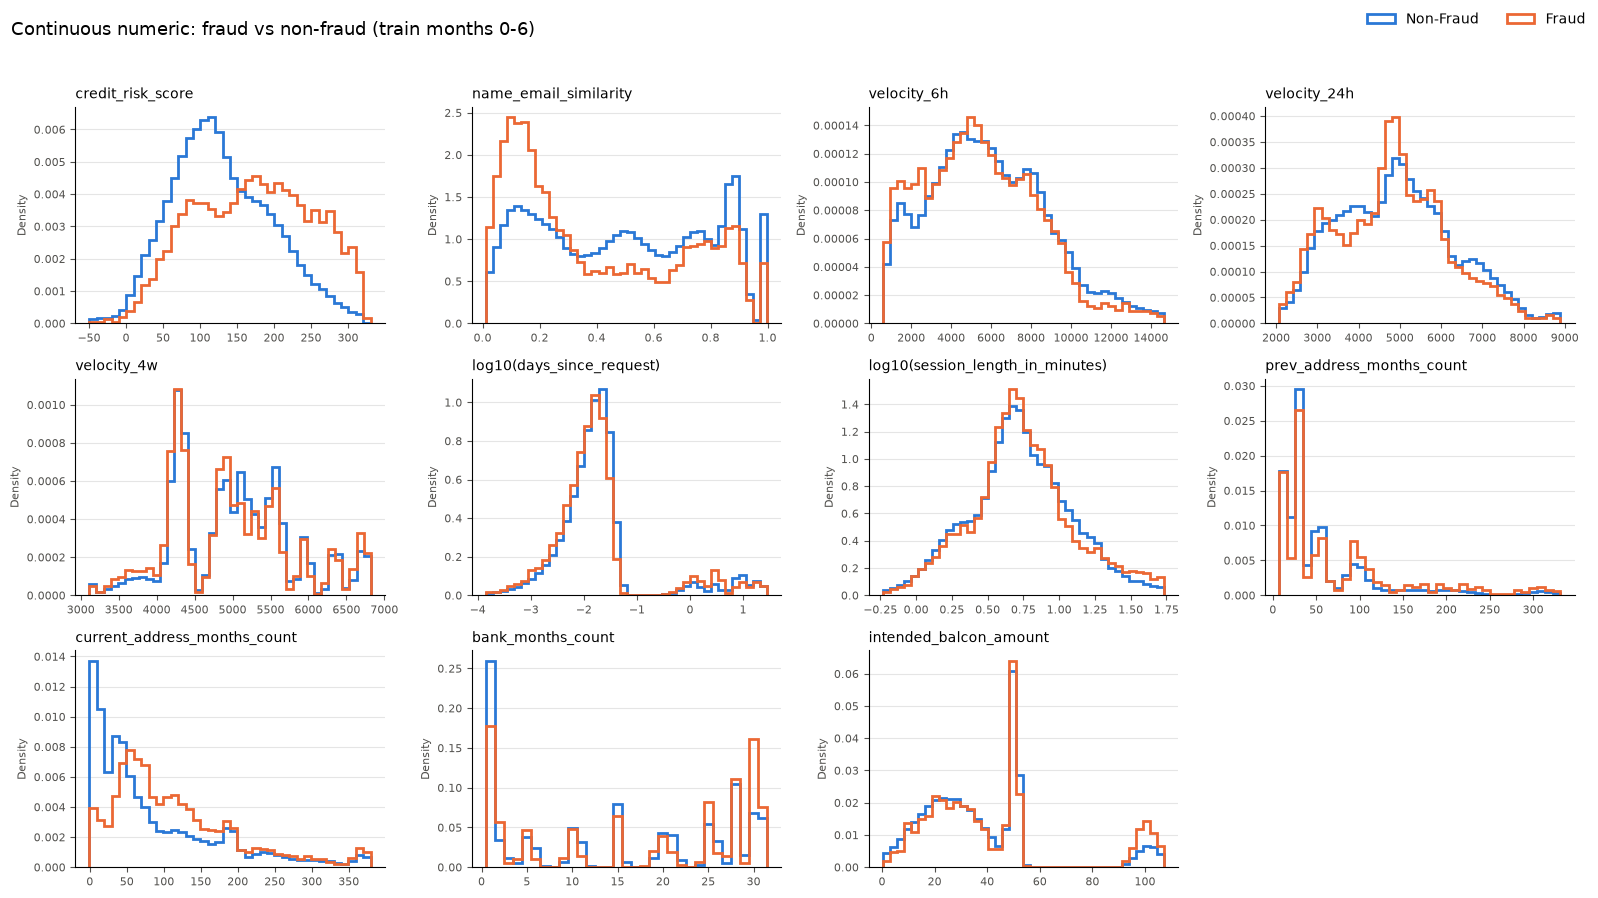

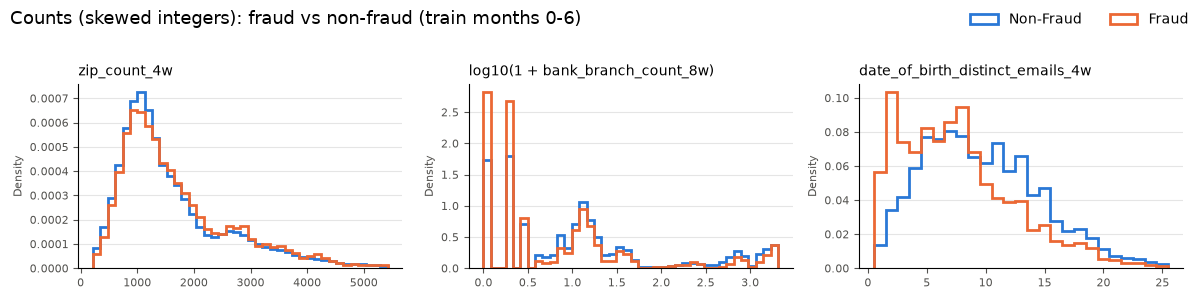

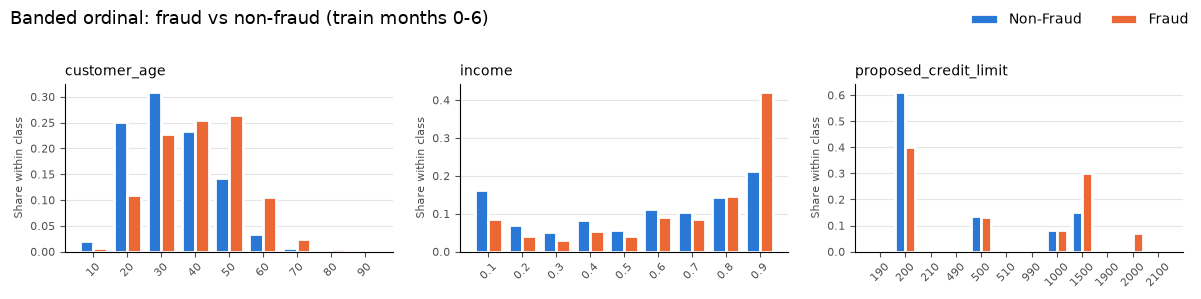

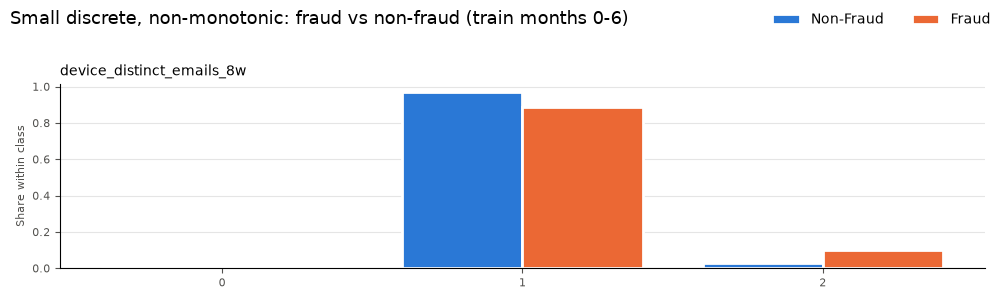

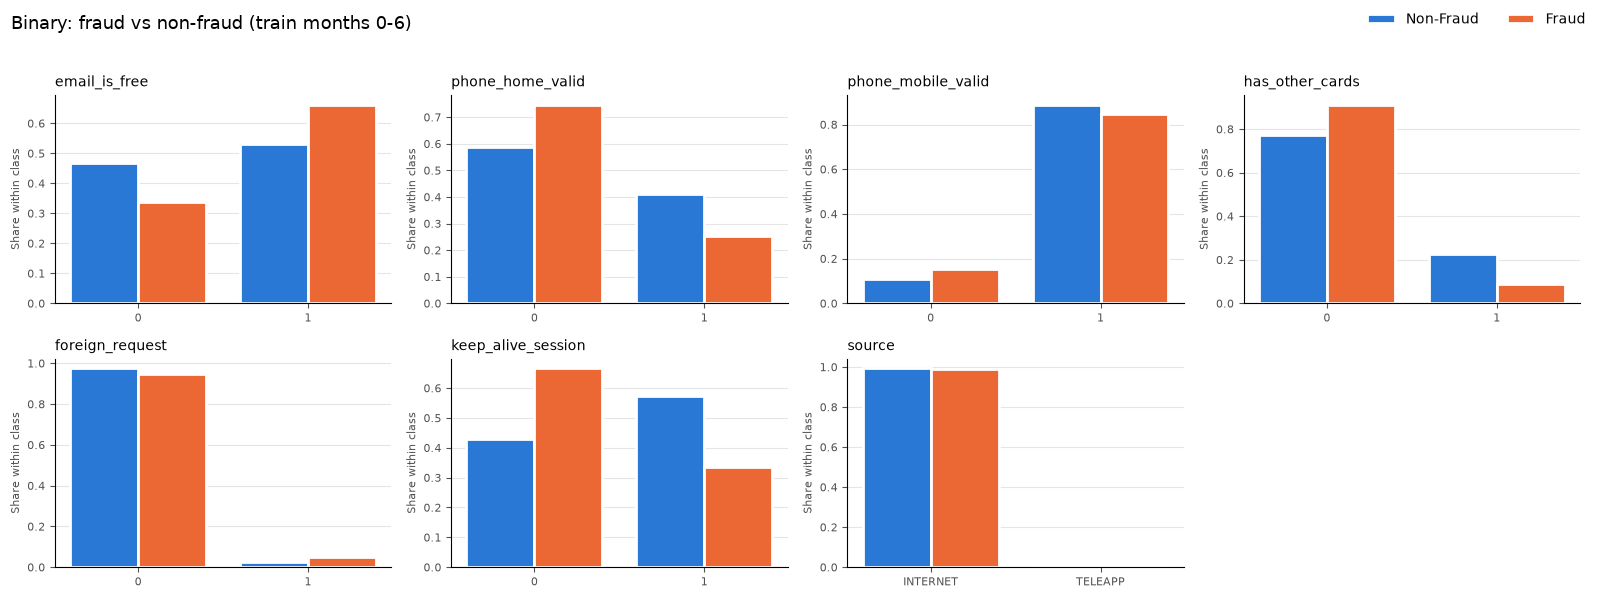

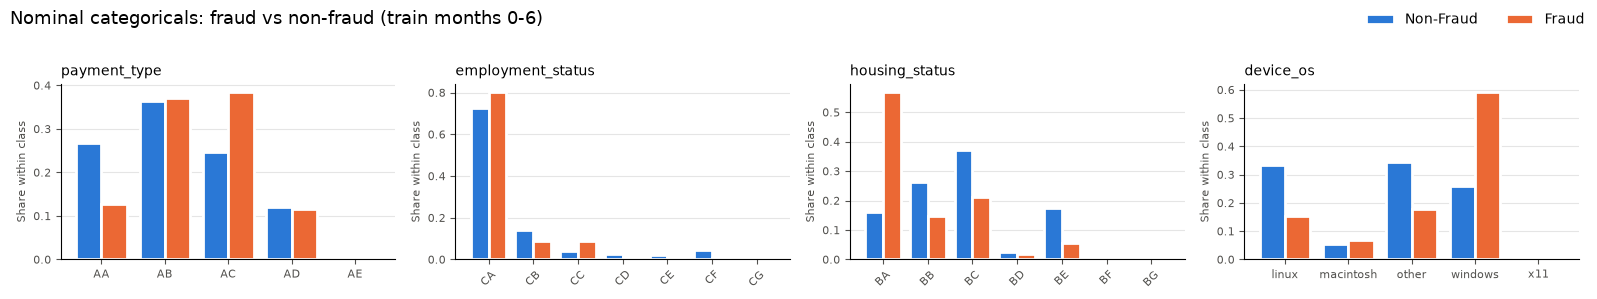

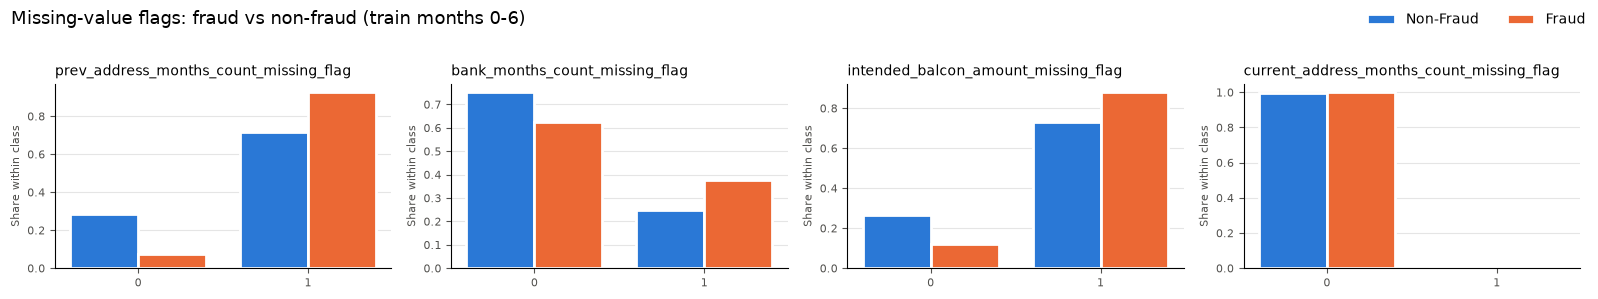

In [17]:
# Grouped by how each feature is treated in Feature Engineering
FEATURE_GROUPS = {
    'Continuous numeric': [
        'credit_risk_score', 'name_email_similarity', 'velocity_6h', 'velocity_24h', 'velocity_4w',
        'days_since_request', 'session_length_in_minutes', 'prev_address_months_count',
        'current_address_months_count', 'bank_months_count', 'intended_balcon_amount',
    ],
    'Counts (skewed integers)': ['zip_count_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w'],
    'Banded ordinal': ['customer_age', 'income', 'proposed_credit_limit'],
    'Small discrete, non-monotonic': ['device_distinct_emails_8w'],
    'Binary': [
        'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'has_other_cards',
        'foreign_request', 'keep_alive_session', 'source',
    ],
    'Nominal categoricals': ['payment_type', 'employment_status', 'housing_status', 'device_os'],
    'Missing-value flags': [
        'prev_address_months_count_missing_flag', 'bank_months_count_missing_flag',
        'intended_balcon_amount_missing_flag', 'current_address_months_count_missing_flag',
    ],
}

grouped_cols = []
for cols in FEATURE_GROUPS.values():
    grouped_cols.extend(cols)

# Every kept column must be in exactly one group; on failure, the message lists the columns that don't match
assert sorted(grouped_cols) == sorted(X_train.columns), set(grouped_cols) ^ set(X_train.columns)

for group, cols in FEATURE_GROUPS.items():
    plot_feature_grid(cols, f'{group}: fraud vs non-fraud (train months 0-6)', ncols=min(4, len(cols)))

## Feature Engineering

Two feature sets are built from the kept columns. Anything learned from the data is fitted on the training months only and then applied to validation to avoid any data leakage issues.

Still to test once models are training:
- `velocity_*` features partly encode time, dropping could improve performance in later months

In [18]:
def encode_source(X):
    X = X.copy()
    X['source'] = (X['source'] == 'TELEAPP').astype(int)
    return X

### XGBoost

XGB trees support categorical variables natively with `enable_categorical=True` and split on thresholds -> no scaling or transformation required

In [19]:
X_train_xgb = encode_source(X_train)
X_val_xgb = encode_source(X_val)

print(X_train_xgb.shape)
print(X_val_xgb.shape)
X_train_xgb.dtypes.value_counts()

(903157, 33)
(96843, 33)


int64       16
float64     13
category     1
category     1
category     1
category     1
Name: count, dtype: int64

### Logistic Regression

- **Standardise:** continuous features, `date_of_birth_distinct_emails_4w`, `customer_age`, `income`
- **Log, then standardise:** `days_since_request`, `zip_count_4w`, `bank_branch_count_8w` (one slope covers the whole range, so long tails would dominate the fit)
- **Median-fill, then standardise:** the address, bank and balcon columns; `session_length_in_minutes` also gets a log
- **One-hot, most common level as the reference:** nominal categoricals (rare levels merged), `proposed_credit_limit` bands, `device_distinct_emails_8w` levels
- **Leave as 0/1:** binaries, `source`, kept missing flags, and a new `income_top_decile` flag for the jump in the top income band

In [20]:
# Each rare level is merged into the level with the closest training fraud rate
RARE_LEVEL_MERGES = {
    'payment_type': {'AE': 'AA'},                # AE 0.38% -> AA 0.51%
    'employment_status': {'CG': 'CA'},           # CG 1.20% -> CA 1.18%
    'housing_status': {'BF': 'BE', 'BG': 'BE'},  # BF 0.39%, BG 0.41% -> BE 0.34%
}

# Fraud jumps from ~2% at 1,500 to 12-17% above it, which a single slope badly underfits
CREDIT_LIMIT_BINS = [-np.inf, 200, 500, 1000, 1500, np.inf]
CREDIT_LIMIT_LABELS = ['<=200', '201-500', '501-1000', '1001-1500', '>1500']

income_top_decile_cutoff = X_train['income'].quantile(0.9)
device_emails_mode = X_train['device_distinct_emails_8w'].mode()[0]


def prepare_lr_features(X):
    X = encode_source(X)
    for col, merges in RARE_LEVEL_MERGES.items():
        X[col] = X[col].astype(str).replace(merges)
    X['device_os'] = X['device_os'].astype(str)

    X['income_top_decile'] = (X['income'] >= income_top_decile_cutoff).astype(int)
    X['proposed_credit_limit'] = pd.cut(X['proposed_credit_limit'], bins=CREDIT_LIMIT_BINS,
                                        labels=CREDIT_LIMIT_LABELS).astype(str)

    # Levels 0 and 2 are both higher-risk than 1, so a single slope would let them cancel out
    X['device_distinct_emails_8w'] = (X['device_distinct_emails_8w'].fillna(device_emails_mode)
                                      .astype(int).astype(str))
    return X


lr_train_input = prepare_lr_features(X_train)
lr_val_input = prepare_lr_features(X_val)

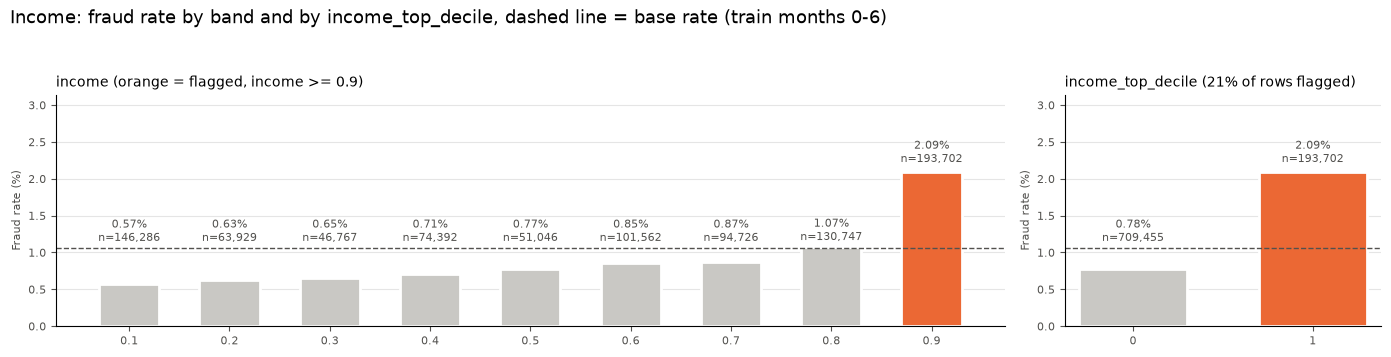

In [21]:
# Fraud rate climbs gently across the income bands, then roughly doubles in the top band, which a single slope underfits.
# Income is already banded, so the 90th-percentile cutoff flags the whole top band rather than exactly 10% of rows
income_df = eda_df.assign(income_top_decile=lr_train_input['income_top_decile'])
muted_color = '#c9c8c4'

fig, (ax_band, ax_flag) = plot.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={'width_ratios': [3, 1]})
plot_fraud_rate(ax_band, 'income', data=income_df)
plot_fraud_rate(ax_flag, 'income_top_decile', data=income_df)

# Grey out what the flag leaves at 0: the lower income bands, and the flag = 0 bar
for bar, band in zip(ax_band.patches, sorted(income_df['income'].unique())):
    if band < income_top_decile_cutoff:
        bar.set_facecolor(muted_color)
ax_flag.patches[0].set_facecolor(muted_color)

ax_band.set_title(f'income (orange = flagged, income >= {income_top_decile_cutoff:g})', fontsize=10, loc='left')
ax_flag.set_title(f"income_top_decile ({income_df['income_top_decile'].mean():.0%} of rows flagged)",
                  fontsize=10, loc='left')
fig.suptitle('Income: fraud rate by band and by income_top_decile, dashed line = base rate (train months 0-6)',
             x=0.01, ha='left', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plot.show()

In [22]:
lr_scale_cols = [
    'credit_risk_score', 'name_email_similarity', 'velocity_6h', 'velocity_24h', 'velocity_4w',
    'date_of_birth_distinct_emails_4w',  # skew ~0.7, mild enough to skip the log
    'customer_age', 'income',
]
lr_log_scale_cols = ['days_since_request', 'zip_count_4w', 'bank_branch_count_8w']
lr_impute_scale_cols = [
    'prev_address_months_count', 'current_address_months_count', 'bank_months_count', 'intended_balcon_amount',
]
lr_impute_log_scale_cols = ['session_length_in_minutes']
lr_onehot_cols = [
    'payment_type', 'employment_status', 'housing_status', 'device_os',
    'proposed_credit_limit', 'device_distinct_emails_8w',
]
lr_passthrough_cols = [
    'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'has_other_cards',
    'foreign_request', 'keep_alive_session', 'source', 'income_top_decile',
    'prev_address_months_count_missing_flag', 'bank_months_count_missing_flag',
    'intended_balcon_amount_missing_flag', 'current_address_months_count_missing_flag',
]

lr_all_cols = (lr_scale_cols + lr_log_scale_cols + lr_impute_scale_cols + lr_impute_log_scale_cols
               + lr_onehot_cols + lr_passthrough_cols)
assert sorted(lr_all_cols) == sorted(lr_train_input.columns), set(lr_all_cols) ^ set(lr_train_input.columns)

# The most common training level is the reference, so the other coefficients compare against a well-populated base
lr_base_levels = [lr_train_input[col].mode()[0] for col in lr_onehot_cols]

log1p = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

lr_preprocessor = ColumnTransformer(
    [
        ('scale', StandardScaler(), lr_scale_cols),
        ('log_scale', make_pipeline(log1p, StandardScaler()), lr_log_scale_cols),
        ('impute_scale', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), lr_impute_scale_cols),
        ('impute_log_scale', make_pipeline(SimpleImputer(strategy='median'), log1p, StandardScaler()),
         lr_impute_log_scale_cols),
        ('onehot', OneHotEncoder(drop=lr_base_levels, handle_unknown='ignore', sparse_output=False), lr_onehot_cols),
        ('binary', 'passthrough', lr_passthrough_cols),
    ],
    verbose_feature_names_out=False,
).set_output(transform='pandas')

In [23]:
X_train_lr = lr_preprocessor.fit_transform(lr_train_input)
X_val_lr = lr_preprocessor.transform(lr_val_input)

print(X_train_lr.shape)
print(X_val_lr.shape)
X_train_lr.describe().T[['mean', 'std', 'min', 'max']].round(2)

(903157, 50)
(96843, 50)


,mean,std,min,max
credit_risk_score,-0.00,1.00,-4.26,3.69
name_email_similarity,0.00,1.00,-1.70,1.74
velocity_6h,-0.00,1.00,-2.01,3.59
velocity_24h,0.00,1.00,-2.54,3.23
velocity_4w,0.00,1.00,-2.78,2.50
date_of_birth_distinct_emails_4w,0.00,1.00,-1.91,5.74
customer_age,0.00,1.00,-1.96,4.64
income,-0.00,1.00,-1.57,1.18
days_since_request,-0.00,1.00,-0.31,6.39
zip_count_4w,0.00,1.00,-10.82,2.63


## Baseline Models

Both models are trained on months 0-6 and evaluated on the validation month (7).

- **ROC AUC / PR AUC** are threshold-free. PR AUC (average precision) is the more informative of the two here, since its chance level is the ~1% base rate rather than 0.5.
- **Precision, Recall, TPR, FPR** need a decision threshold. Following the BAF benchmark convention, the threshold is set so the overall FPR on the validation month is 5%, which puts both models at the same operating point. Recall and TPR are the same quantity.
- **Predictive equality** compares FPR between age groups (`customer_age` < 50 vs >= 50, as in the BAF paper), reported as the lower FPR divided by the higher. 1.0 means both groups are wrongly flagged at the same rate.
- **Predictive equality (all ages)** applies the same idea across every decade bucket of `customer_age`: the lowest bucket FPR divided by the highest. The 90s bucket has only 3 validation rows, so it is merged into 80+.

The threshold is picked on the validation month itself, so the threshold metrics are slightly optimistic; a held-out test month is needed for an unbiased estimate.

In [24]:
TARGET_FPR = 0.05
AGE_GROUP_CUTOFF = 50

# customer_age is binned by decade. The 90s bucket is too small for a meaningful FPR (3 validation rows),
# so it is merged into 80+
AGE_BUCKET_CAP = 80
AGE_BUCKET_LABELS = {}
for decade in range(10, AGE_BUCKET_CAP + 1, 10):
    if decade < AGE_BUCKET_CAP:
        AGE_BUCKET_LABELS[decade] = f'{decade}-{decade + 9}'
    else:
        AGE_BUCKET_LABELS[decade] = f'{decade}+'


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    # Lowest threshold whose FPR stays at or below the target
    fpr, _, thresholds = roc_curve(y_true, scores)
    return thresholds[np.searchsorted(fpr, target_fpr, side='right') - 1]


def false_positive_rate(y_true, y_pred):
    return y_pred[y_true == 0].mean()


def fpr_by_age_bucket(y_true, y_pred, age):
    # Only non-fraud rows can be false positives, so each bucket's FPR is the share of its non-fraud rows flagged
    non_fraud = y_true == 0
    buckets = pd.Series(np.minimum(age[non_fraud], AGE_BUCKET_CAP)).map(AGE_BUCKET_LABELS)
    flagged = pd.Series(y_pred[non_fraud])

    table = flagged.groupby(buckets).agg(non_fraud='size', false_positives='sum')
    table = table.reindex(list(AGE_BUCKET_LABELS.values())).rename_axis('age_bucket')
    table['fpr'] = table['false_positives'] / table['non_fraud']
    return table


def evaluate_model(y_true, scores, age):
    threshold = threshold_at_fpr(y_true, scores)
    y_pred = (scores >= threshold).astype(int)
    recall = recall_score(y_true, y_pred)

    older = age >= AGE_GROUP_CUTOFF
    fpr_younger = false_positive_rate(y_true[~older], y_pred[~older])
    fpr_older = false_positive_rate(y_true[older], y_pred[older])
    bucket_fpr = fpr_by_age_bucket(y_true, y_pred, age)['fpr']

    return {
        'ROC AUC': roc_auc_score(y_true, scores),
        'PR AUC': average_precision_score(y_true, scores),
        'Threshold': threshold,
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall,
        'TPR': recall,
        'FPR': false_positive_rate(y_true, y_pred),
        f'FPR age < {AGE_GROUP_CUTOFF}': fpr_younger,
        f'FPR age >= {AGE_GROUP_CUTOFF}': fpr_older,
        'Predictive equality': min(fpr_younger, fpr_older) / max(fpr_younger, fpr_older),
        'Predictive equality (all ages)': bucket_fpr.min() / bucket_fpr.max(),
    }

### Logistic Regression (balanced class weights)

In [25]:
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000)
lr_model.fit(X_train_lr, y_train)

lr_val_scores = lr_model.predict_proba(X_val_lr)[:, 1]

### XGBoost (scale_pos_weight)

In [26]:
# Ratio of negatives to positives in the training months
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.1f}")

xgb_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True,
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train_xgb, y_train)

xgb_val_scores = xgb_model.predict_proba(X_val_xgb)[:, 1]

scale_pos_weight: 93.1


### Results

In [27]:
val_scores = {
    'Logistic Regression': lr_val_scores,
    'XGBoost': xgb_val_scores,
}

y_val_array = y_val.to_numpy()
val_age = X_val['customer_age'].to_numpy()

results = pd.DataFrame({
    name: evaluate_model(y_val_array, scores, val_age)
    for name, scores in val_scores.items()
}).T
results.round(4)

,ROC AUC,PR AUC,Threshold,Precision,Recall,TPR,FPR,FPR age < 50,FPR age >= 50,Predictive equality,Predictive equality (all ages)
Logistic Regression,0.8917,0.2052,0.7493,0.1412,0.5469,0.5469,0.0498,0.0394,0.1203,0.3279,0.0411
XGBoost,0.8763,0.1769,0.6679,0.1320,0.5077,0.5077,0.0500,0.0385,0.1275,0.3021,0.0674


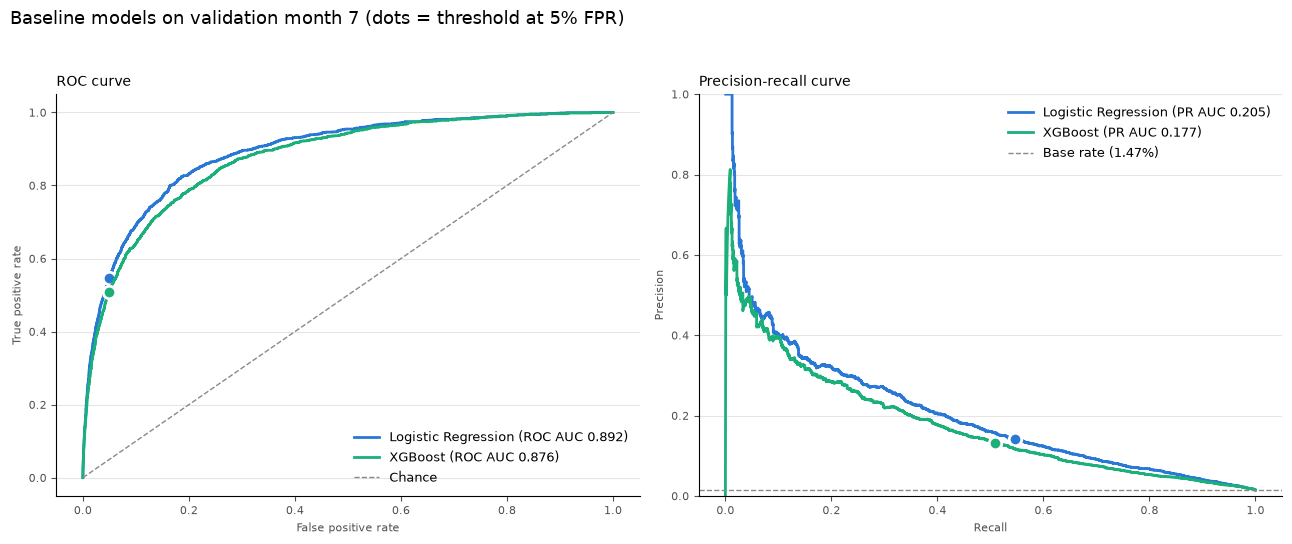

In [28]:
MODEL_COLORS = {'Logistic Regression': '#2a78d6', 'XGBoost': '#1baf7a'}
REFERENCE_COLOR = '#8a8984'


def plot_roc_pr(model_names, title):
    fig, (ax_roc, ax_pr) = plot.subplots(1, 2, figsize=(13, 5.5))

    for name in model_names:
        scores = val_scores[name]
        color = MODEL_COLORS[name]
        row = results.loc[name]
        # Dot marking where the decision threshold puts this model on each curve
        threshold_marker = dict(marker='o', linestyle='none', color=color, markersize=9,
                                markeredgecolor='white', markeredgewidth=2)

        fpr, tpr, _ = roc_curve(y_val_array, scores)
        ax_roc.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (ROC AUC {row['ROC AUC']:.3f})")
        ax_roc.plot(row['FPR'], row['TPR'], **threshold_marker)

        # Skip the final (recall 0, precision 1) point sklearn appends, which draws a vertical spike at the edge
        precision, recall, _ = precision_recall_curve(y_val_array, scores)
        ax_pr.plot(recall[:-1], precision[:-1], color=color, linewidth=2,
                   label=f"{name} (PR AUC {row['PR AUC']:.3f})")
        ax_pr.plot(row['Recall'], row['Precision'], **threshold_marker)

    ax_roc.plot([0, 1], [0, 1], linestyle='--', linewidth=1, color=REFERENCE_COLOR, label='Chance')
    style_axis(ax_roc, 'ROC curve', 'True positive rate')
    ax_roc.set_xlabel('False positive rate', fontsize=8, color='#52514e')
    ax_roc.legend(loc='lower right', frameon=False, fontsize=9)

    base_rate = y_val_array.mean()
    ax_pr.axhline(base_rate, linestyle='--', linewidth=1, color=REFERENCE_COLOR,
                  label=f'Base rate ({base_rate:.2%})')
    style_axis(ax_pr, 'Precision-recall curve', 'Precision')
    ax_pr.set_xlabel('Recall', fontsize=8, color='#52514e')
    ax_pr.set_ylim(0, 1)
    ax_pr.legend(loc='upper right', frameon=False, fontsize=9)

    fig.suptitle(title, x=0.01, ha='left', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    return fig


plot_roc_pr(list(val_scores), f'Baseline models on validation month 7 (dots = threshold at {TARGET_FPR:.0%} FPR)')
plot.show()

## MLflow Tracking

Each baseline is logged as its own run with its parameters, validation metrics, ROC/PR and confusion-matrix plots, a classification report, the FPR in each age bucket (as metrics and a CSV), and the model with a signature and input example. Threshold metrics and the report use the same 5% FPR threshold as the results table.

Both models are logged with the `sklearn` flavor and `pyfunc_predict_fn='predict_proba'`, so a loaded pyfunc model returns fraud probabilities rather than labels at a 0.5 cutoff. The XGBoost model is logged behind a step that restores its categorical dtypes, since served JSON input arrives as strings. The logistic regression model expects the already-preprocessed `X_*_lr` columns.

In [29]:
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("BAF account creation fraud detection")

# MLflow metric names can't contain characters like < or >=
METRIC_NAMES = {
    'ROC AUC': 'roc_auc',
    'PR AUC': 'pr_auc',
    'Precision': 'precision',
    'Recall': 'recall',
    'TPR': 'tpr',
    'FPR': 'fpr',
    f'FPR age < {AGE_GROUP_CUTOFF}': f'fpr_age_under_{AGE_GROUP_CUTOFF}',
    f'FPR age >= {AGE_GROUP_CUTOFF}': f'fpr_age_{AGE_GROUP_CUTOFF}_plus',
    'Predictive equality': 'predictive_equality',
    'Predictive equality (all ages)': 'predictive_equality_all_ages',
}
AGE_BUCKET_METRIC_NAMES = {label: 'fpr_age_' + label.replace('-', '_').replace('+', '_plus')
                           for label in AGE_BUCKET_LABELS.values()}
CLASS_NAMES = ['Non-Fraud', 'Fraud']


# Served requests arrive as JSON, so XGBoost's categorical columns come in as strings.
# Logging the model behind this cast restores the training categories before predicting.
XGB_CATEGORY_DTYPES = {col: X_train_xgb[col].dtype for col in X_train_xgb.select_dtypes('category').columns}


def restore_categories(X):
    return X.astype(XGB_CATEGORY_DTYPES)


def log_model_run(name, model, X_val_model, serving_model=None, run_name=None, params=None, extra_params=None):
    if serving_model is None:
        serving_model = model
    if run_name is None:
        run_name = f'{name} baseline'
    if params is None:
        params = model.get_params()

    row = results.loc[name]
    y_pred = (val_scores[name] >= row['Threshold']).astype(int)
    report = classification_report(y_val_array, y_pred, target_names=CLASS_NAMES, digits=4)
    age_fpr = fpr_by_age_bucket(y_val_array, y_pred, val_age)

    run_params = {
        'train_months': train_months,
        'val_months': val_months,
        'n_features': X_val_model.shape[1],
        'target_fpr': TARGET_FPR,
        'decision_threshold': row['Threshold'],
    }
    if extra_params:
        run_params.update(extra_params)

    metrics = {metric: row[column] for column, metric in METRIC_NAMES.items()}
    for bucket, fpr in age_fpr['fpr'].items():
        metrics[AGE_BUCKET_METRIC_NAMES[bucket]] = fpr

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_params(run_params)
        mlflow.log_metrics(metrics)

        fig = plot_roc_pr([name], f'{name} on validation month 7 (dot = threshold at {TARGET_FPR:.0%} FPR)')
        mlflow.log_figure(fig, 'roc_pr_curves.png')
        plot.close(fig)

        fig, ax = plot.subplots(figsize=(5, 4.5))
        ConfusionMatrixDisplay.from_predictions(y_val_array, y_pred, display_labels=CLASS_NAMES,
                                                cmap='Blues', colorbar=False, values_format=',', ax=ax)
        ax.set_title(f'{name} at {TARGET_FPR:.0%} FPR threshold', fontsize=10, loc='left')
        fig.tight_layout()
        mlflow.log_figure(fig, 'confusion_matrix.png')
        plot.close(fig)

        mlflow.log_text(report, 'classification_report.txt')
        mlflow.log_text(age_fpr.to_csv(), 'fpr_by_age_bucket.csv')

        input_example = X_val_model.head(5)
        signature = infer_signature(input_example, serving_model.predict_proba(input_example))
        mlflow.sklearn.log_model(serving_model, name='model', signature=signature, input_example=input_example,
                                 pyfunc_predict_fn='predict_proba')

    print(f'{name} (threshold {row["Threshold"]:.4f})')
    print(report)

In [30]:
log_model_run('Logistic Regression', lr_model, X_val_lr)
log_model_run('XGBoost', xgb_model, X_val_xgb,
              serving_model=make_pipeline(FunctionTransformer(restore_categories), xgb_model))

c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/10 19:00:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary

🏃 View run Logistic Regression baseline at: http://localhost:5000/#/experiments/1/runs/c436f344607c4f09b54ba53a93e11b53
🧪 View experiment at: http://localhost:5000/#/experiments/1
Logistic Regression (threshold 0.7493)
              precision    recall  f1-score   support

   Non-Fraud     0.9929    0.9502    0.9711     95415
       Fraud     0.1412    0.5469    0.2244      1428

    accuracy                         0.9442     96843
   macro avg     0.5670    0.7486    0.5977     96843
weighted avg     0.9804    0.9442    0.9601     96843



c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/10 19:01:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary

🏃 View run XGBoost baseline at: http://localhost:5000/#/experiments/1/runs/03cbb6123aaf429bbd4be02bb18428e7
🧪 View experiment at: http://localhost:5000/#/experiments/1
XGBoost (threshold 0.6679)
              precision    recall  f1-score   support

   Non-Fraud     0.9923    0.9500    0.9707     95415
       Fraud     0.1320    0.5077    0.2096      1428

    accuracy                         0.9435     96843
   macro avg     0.5622    0.7289    0.5901     96843
weighted avg     0.9796    0.9435    0.9595     96843



## Hyperparameter Tuning

Both models are tuned with an Optuna random search (`RandomSampler`, seeded). Each trial trains on months 0-6 and is scored on validation month 7. The objective is **recall at the 5% FPR threshold**, the BAF benchmark's headline metric.

Search spaces. Optuna can't combine `step` with `log=True`, so the log-uniform ranges are continuous. The uniform ranges are discretised; nearby values make no measurable difference, so a finer grid would only spread trials out.

| Model | Hyperparameter | Range | Distribution | Step |
|---|---|---|---|---|
| LR | `C` | 1e-4 to 1e2 | Log-uniform | continuous |
| LR | `l1_ratio` | 0 to 1 | Uniform | 0.05 |
| LR | `class_weight` | None, balanced | Categorical | - |
| XGB | `learning_rate` | 0.01 to 0.3 | Log-uniform | continuous |
| XGB | `max_depth` | 3 to 10 | Uniform integer | 1 |
| XGB | `min_child_weight` | 1 to 100 | Log-uniform | continuous |
| XGB | `subsample` | 0.5 to 1.0 | Uniform | 0.05 |
| XGB | `colsample_bytree` | 0.5 to 1.0 | Uniform | 0.05 |
| XGB | `reg_lambda` | 1e-3 to 100 | Log-uniform | continuous |
| XGB | `reg_alpha` | 1e-3 to 10 | Log-uniform | continuous |
| XGB | `gamma` | 1e-3 to 10 | Log-uniform | continuous |
| XGB | `scale_pos_weight` | 1 to 100 | Log-uniform | continuous |

- **Logistic regression** needs the `saga` solver for elastic-net. Its step size ignores sample weights, so with `class_weight='balanced'` (~46x weight on fraud rows) it diverges. The balanced case is therefore fitted with the weights rescaled to at most 1 and `C` scaled up by the same factor, which is the same objective.
- **XGBoost** isn't given a fixed `n_estimators`. A low `learning_rate` needs far more trees than a high one, so each trial grows up to 2,000 trees and early-stops on validation PR AUC after 100 rounds without improvement. Trials train on the GPU, and each model is switched to CPU before scoring and logging.

**MLflow:** each search is one parent run (`<model> random search`) with one nested run per trial. Trial runs hold the sampled parameters, every validation metric and the fit time. The parent holds the search space, the best trial's parameters, a `trials.csv` export and a search-history plot. The best model from each search is then logged as its own top-level run (`<model> (tuned)`), with the same plots, report and model artifact as the baselines, so it sits next to them in the experiment.

Both the hyperparameters and the threshold are now chosen on validation month 7, so the validation metrics of the tuned models are optimistic. The held-out test month caveat above applies even more here.

In [31]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

TUNING_METRIC = 'Recall'  # recall (TPR) at the TARGET_FPR threshold
SEARCH_SEED = 42

MODEL_COLORS.update({'Logistic Regression (tuned)': '#7b4fd6', 'XGBoost (tuned)': '#eb6834'})


def plot_search_history(study, title):
    values = np.array([trial.value for trial in study.trials])
    fig, ax = plot.subplots(figsize=(9, 4))
    ax.scatter(np.arange(len(values)), values, s=16, color=REFERENCE_COLOR, label='Trial')
    ax.plot(np.maximum.accumulate(values), drawstyle='steps-post', color='#eb6834', linewidth=2, label='Best so far')
    style_axis(ax, title, f'{TUNING_METRIC} at {TARGET_FPR:.0%} FPR')
    ax.set_xlabel('Trial', fontsize=8, color='#52514e')
    ax.legend(loc='lower right', frameon=False, fontsize=9)
    fig.tight_layout()
    return fig


def run_random_search(name, suggest_params, fit_model, X_val_model, n_trials):
    # fit_model(params) returns the fitted model and a dict of extra per-trial metrics to log.
    # The best model is kept in memory so it can be logged with full artifacts without refitting.
    best = {}

    def objective(trial):
        params = suggest_params(trial)
        with mlflow.start_run(run_name=f'{name} trial {trial.number}', nested=True):
            start = time.perf_counter()
            model, fit_metrics = fit_model(params)
            fit_seconds = time.perf_counter() - start

            scores = model.predict_proba(X_val_model)[:, 1]
            metrics = evaluate_model(y_val_array, scores, val_age)

            trial_metrics = {metric: metrics[column] for column, metric in METRIC_NAMES.items()}
            trial_metrics.update(fit_metrics)
            trial_metrics['fit_seconds'] = fit_seconds

            mlflow.log_params({**params, 'decision_threshold': metrics['Threshold']})
            mlflow.log_metrics(trial_metrics)

        value = metrics[TUNING_METRIC]
        if not best or value > best['value']:
            best.update(value=value, trial=trial.number, params=params, model=model, scores=scores)
        return value

    study = optuna.create_study(study_name=f'{name} random search', direction='maximize',
                                sampler=optuna.samplers.RandomSampler(seed=SEARCH_SEED))

    with mlflow.start_run(run_name=f'{name} random search') as search_run:
        mlflow.log_params({
            'sampler': 'RandomSampler',
            'sampler_seed': SEARCH_SEED,
            'n_trials': n_trials,
            'tuning_metric': METRIC_NAMES[TUNING_METRIC],
            'train_months': train_months,
            'val_months': val_months,
            'target_fpr': TARGET_FPR,
        })
        study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

        # Every trial samples from the same distributions, so the first one documents the search space
        search_space = study.trials[0].distributions
        mlflow.log_params({f'space_{param}': repr(dist) for param, dist in search_space.items()})

        best_params = {'best_trial': study.best_trial.number}
        for param, value in study.best_params.items():
            best_params[f'best_{param}'] = value
        mlflow.log_params(best_params)
        mlflow.log_metric(f'best_{METRIC_NAMES[TUNING_METRIC]}', study.best_value)
        mlflow.log_text(study.trials_dataframe().to_csv(index=False), 'trials.csv')

        fig = plot_search_history(study, f'{name} random search on validation month 7')
        mlflow.log_figure(fig, 'search_history.png')
        plot.show()

    best['search_run_id'] = search_run.info.run_id
    print(f"Best trial {best['trial']}: {TUNING_METRIC} {best['value']:.4f}")
    print(best['params'])
    return study, best


def log_tuned_run(name, best, X_val_model, extra_params=None, **log_kwargs):
    val_scores[name] = best['scores']
    results.loc[name] = pd.Series(evaluate_model(y_val_array, best['scores'], val_age))

    run_params = {
        'tuning_metric': METRIC_NAMES[TUNING_METRIC],
        'best_trial': best['trial'],
        'search_run_id': best['search_run_id'],
    }
    if extra_params:
        run_params.update(extra_params)
    log_model_run(name, best['model'], X_val_model, run_name=name, extra_params=run_params, **log_kwargs)

### Logistic Regression

  0%|          | 0/50 [00:00<?, ?it/s]

🏃 View run Logistic Regression trial 0 at: http://localhost:5000/#/experiments/1/runs/eda1b18133094ccd80e5e7646f43e01d
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Logistic Regression trial 1 at: http://localhost:5000/#/experiments/1/runs/0a794fe37a4949c9b33600e0c04e9f09
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Logistic Regression trial 2 at: http://localhost:5000/#/experiments/1/runs/a78d56b0c0bb4e3fac1f024e602adfe6
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Logistic Regression trial 3 at: http://localhost:5000/#/experiments/1/runs/f24bf4c1aac046e69200ac27d68b8ee9
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Logistic Regression trial 4 at: http://localhost:5000/#/experiments/1/runs/8df2ccef6c084e67be5969741a2008e1
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Logistic Regression trial 5 at: http://localhost:5000/#/experiments/1/runs/471a1a43b30449159bf

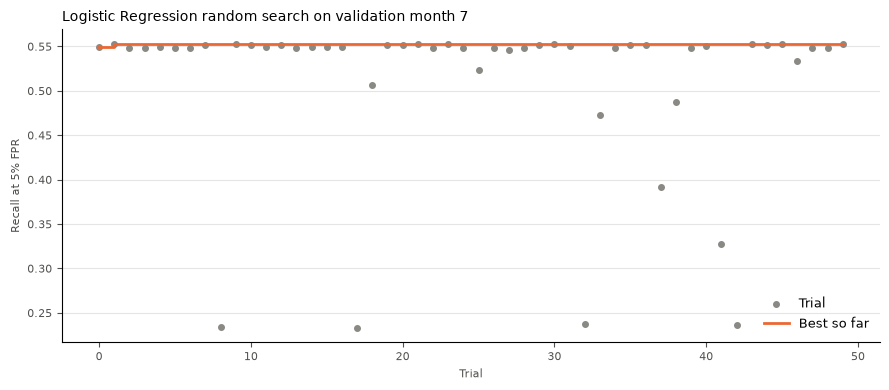

🏃 View run Logistic Regression random search at: http://localhost:5000/#/experiments/1/runs/8a919066f6204a16925d4fe9b0cae866
🧪 View experiment at: http://localhost:5000/#/experiments/1
Best trial 21: Recall 0.5532
{'C': 0.007343344964174942, 'l1_ratio': 0.30000000000000004, 'class_weight': None}


In [32]:
LR_N_TRIALS = 50  # ~5-30s per trial

n_fraud = y_train.sum()
n_non_fraud = len(y_train) - n_fraud
# 'balanced' weights each class by n / (2 * class count). Scaling every weight down by the fraud weight and C up
# by the same factor leaves the objective unchanged but keeps saga's step size stable.
BALANCED_C_SCALE = len(y_train) / (2 * n_fraud)
BALANCED_SAGA_WEIGHTS = {0: float(n_fraud / n_non_fraud), 1: 1.0}


def suggest_lr_params(trial):
    return {
        'C': trial.suggest_float('C', 1e-4, 1e2, log=True),
        'l1_ratio': trial.suggest_float('l1_ratio', 0.0, 1.0, step=0.05),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
    }


def make_lr_model(C, l1_ratio, class_weight):
    if class_weight == 'balanced':
        C = C * BALANCED_C_SCALE
        class_weight = BALANCED_SAGA_WEIGHTS
    return LogisticRegression(C=C, l1_ratio=l1_ratio, class_weight=class_weight, solver='saga',
                              max_iter=1000, random_state=42)


def fit_lr(params):
    model = make_lr_model(**params).fit(X_train_lr, y_train)
    return model, {'n_iter': model.n_iter_[0]}


lr_study, lr_best = run_random_search('Logistic Regression', suggest_lr_params, fit_lr, X_val_lr, LR_N_TRIALS)

In [33]:
lr_tuned = lr_best['model']

# Log C and class_weight as sampled, so they read the same as the baseline and trial runs; the values saga
# was actually fitted with are kept alongside
lr_tuned_params = {
    **lr_tuned.get_params(),
    **lr_best['params'],
    'saga_C': lr_tuned.C,
    'saga_class_weight': lr_tuned.class_weight,
}
log_tuned_run('Logistic Regression (tuned)', lr_best, X_val_lr, params=lr_tuned_params)

c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/10 19:15:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary

🏃 View run Logistic Regression (tuned) at: http://localhost:5000/#/experiments/1/runs/bfd58a67684c453f9ffbe6522b51bfad
🧪 View experiment at: http://localhost:5000/#/experiments/1
Logistic Regression (tuned) (threshold 0.0329)
              precision    recall  f1-score   support

   Non-Fraud     0.9930    0.9500    0.9710     95415
       Fraud     0.1421    0.5532    0.2262      1428

    accuracy                         0.9442     96843
   macro avg     0.5676    0.7516    0.5986     96843
weighted avg     0.9805    0.9442    0.9601     96843



### XGBoost

  0%|          | 0/100 [00:00<?, ?it/s]

🏃 View run XGBoost trial 0 at: http://localhost:5000/#/experiments/1/runs/f1cd5d945bf14c559c631c84e0cb6252
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run XGBoost trial 1 at: http://localhost:5000/#/experiments/1/runs/aedd39ff16e84359be9b459692f3fa6e
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run XGBoost trial 2 at: http://localhost:5000/#/experiments/1/runs/56ef6b9c209947bb9fcf7a341de59d52
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run XGBoost trial 3 at: http://localhost:5000/#/experiments/1/runs/0d8d5809dc894490b0be253ceab9d38b
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run XGBoost trial 4 at: http://localhost:5000/#/experiments/1/runs/4ceebb6e9c0c480ba08297ba2dcb904c
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run XGBoost trial 5 at: http://localhost:5000/#/experiments/1/runs/5901f5b220464f81b33501bc1529af49
🧪 View experiment at: http://localhost:5000/#/experiments/

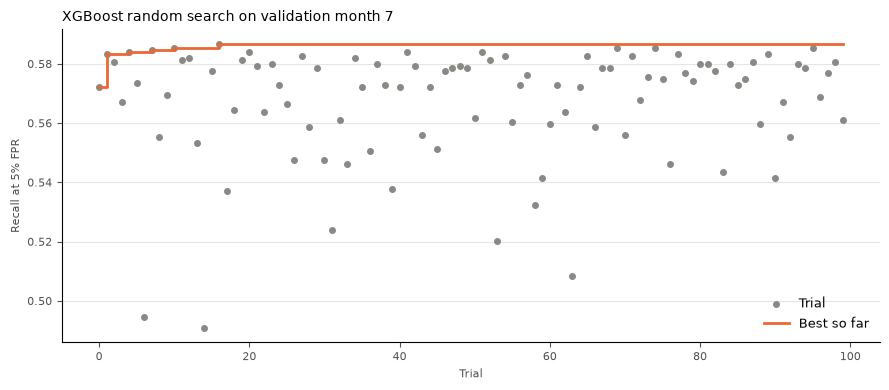

🏃 View run XGBoost random search at: http://localhost:5000/#/experiments/1/runs/e816cf549d2a4d328cb0b892434c7690
🧪 View experiment at: http://localhost:5000/#/experiments/1
Best trial 16: Recall 0.5868
{'learning_rate': 0.02634777514406047, 'max_depth': 3, 'min_child_weight': 16.562605893335956, 'subsample': 0.75, 'colsample_bytree': 0.5, 'reg_lambda': 0.024730467210999134, 'reg_alpha': 4.295992790539128, 'gamma': 0.009083381663660588, 'scale_pos_weight': 1.9489008462344248}


In [34]:
XGB_N_TRIALS = 100  # ~2-30s per trial on the GPU
XGB_DEVICE = 'cuda'  # 'cpu' also works, ~2-3x slower
XGB_MAX_ROUNDS = 2000
XGB_EARLY_STOPPING_ROUNDS = 100


def suggest_xgb_params(trial):
    return {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 100, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0, step=0.05),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0, step=0.05),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 100, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'gamma': trial.suggest_float('gamma', 1e-3, 10, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 100, log=True),
    }


def fit_xgb(params):
    model = XGBClassifier(
        **params,
        n_estimators=XGB_MAX_ROUNDS,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
        eval_metric='aucpr',
        enable_categorical=True,
        tree_method='hist',
        device=XGB_DEVICE,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train_xgb, y_train, eval_set=[(X_val_xgb, y_val)], verbose=False)
    # Predict on the CPU, where the pandas input lives, and so the logged model doesn't need a GPU
    model.set_params(device='cpu')
    return model, {'best_iteration': model.best_iteration}


xgb_study, xgb_best = run_random_search('XGBoost', suggest_xgb_params, fit_xgb, X_val_xgb, XGB_N_TRIALS)

In [35]:
xgb_tuned = xgb_best['model']

log_tuned_run('XGBoost (tuned)', xgb_best, X_val_xgb,
              serving_model=make_pipeline(FunctionTransformer(restore_categories), xgb_tuned),
              extra_params={'best_iteration': xgb_tuned.best_iteration, 'train_device': XGB_DEVICE})

c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/10 19:23:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary

🏃 View run XGBoost (tuned) at: http://localhost:5000/#/experiments/1/runs/2520eda4fdc14fe3ae0bcf8f470f477e
🧪 View experiment at: http://localhost:5000/#/experiments/1
XGBoost (tuned) (threshold 0.0672)
              precision    recall  f1-score   support

   Non-Fraud     0.9935    0.9502    0.9714     95415
       Fraud     0.1500    0.5868    0.2390      1428

    accuracy                         0.9449     96843
   macro avg     0.5718    0.7685    0.6052     96843
weighted avg     0.9811    0.9449    0.9606     96843



### Baseline vs Tuned

In [36]:
results.round(4)

,ROC AUC,PR AUC,Threshold,Precision,Recall,TPR,FPR,FPR age < 50,FPR age >= 50,Predictive equality,Predictive equality (all ages)
Logistic Regression,0.8917,0.2052,0.7493,0.1412,0.5469,0.5469,0.0498,0.0394,0.1203,0.3279,0.0411
XGBoost,0.8763,0.1769,0.6679,0.1320,0.5077,0.5077,0.0500,0.0385,0.1275,0.3021,0.0674
Logistic Regression (tuned),0.8906,0.2045,0.0329,0.1421,0.5532,0.5532,0.0500,0.0389,0.1248,0.3120,0.0268
XGBoost (tuned),0.9014,0.2276,0.0672,0.1500,0.5868,0.5868,0.0498,0.0395,0.1191,0.3319,0.0487


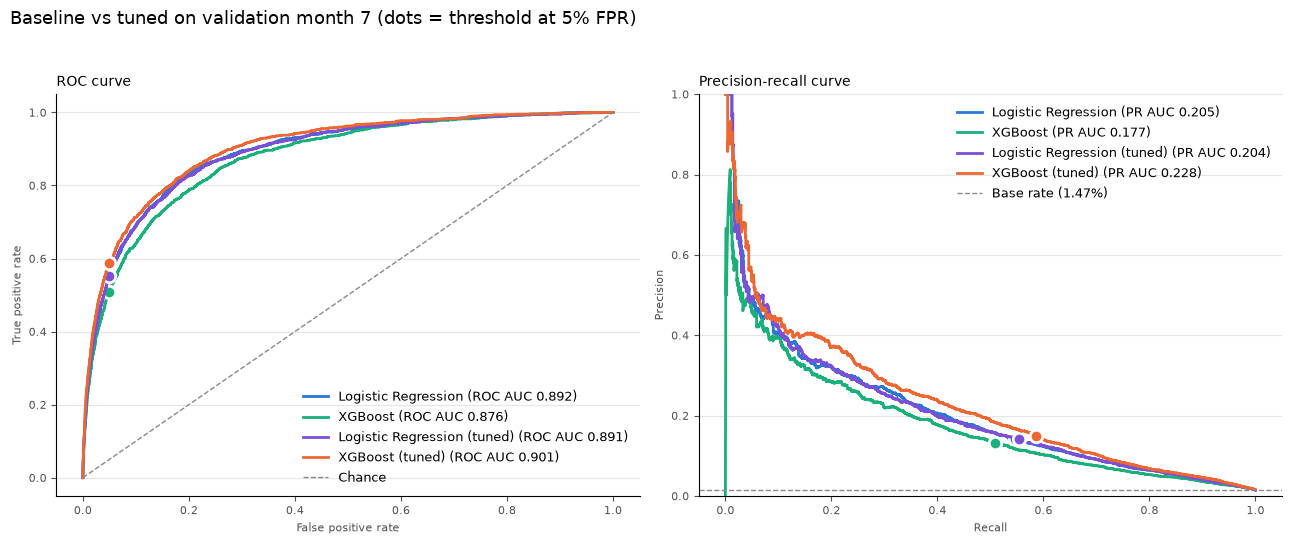

In [37]:
plot_roc_pr(list(val_scores), f'Baseline vs tuned on validation month 7 (dots = threshold at {TARGET_FPR:.0%} FPR)')
plot.show()

## Removing Age as a Feature

`customer_age` is the protected attribute, so both tuned models are retrained without it and compared with the tuned models that use it. The tuned hyperparameters are kept as they are. XGBoost re-runs early stopping, so its tree count can change. Every model is evaluated at the same 5% FPR operating point.

Predictive equality is reported two ways:
- **< 50 vs >= 50:** the BAF paper's binary split, as in the results above.
- **All age buckets:** FPR within each decade of `customer_age`, then the lowest bucket FPR divided by the highest. 80+ (90s merged in) has under 100 non-fraud validation rows, so its FPR is noisy; the plot shows 95% Wilson intervals.

Dropping the column doesn't remove age information. Other features carry some of it: `date_of_birth_distinct_emails_4w` has a Spearman correlation of 0.45 with age, `employment_status` CC applicants average 52 against ~33 for the other levels, and `housing_status` varies by up to 15 years. Any remaining FPR gap across ages can come through these proxies, so the FPRs are measured rather than assumed.

**MLflow:** each retrained model is logged as `<model> (tuned, no age)` with the same artifacts as the other runs. An `Age removal fairness comparison` run holds the with/without-age metric table, the FPR-by-bucket table and plot, and the change in each metric when age is removed.

In [38]:
AGE_COLS = ['customer_age']
AGE_COMPARISON_MODELS = [
    'Logistic Regression (tuned)', 'Logistic Regression (tuned, no age)',
    'XGBoost (tuned)', 'XGBoost (tuned, no age)',
]
MODEL_COLORS.update({'Logistic Regression (tuned, no age)': '#c79a1e', 'XGBoost (tuned, no age)': '#0f8a8a'})

# Re-score the existing models so they pick up the all-ages predictive equality column
results = pd.DataFrame({
    name: evaluate_model(y_val_array, scores, val_age)
    for name, scores in val_scores.items()
}).T

X_train_xgb_no_age = X_train_xgb.drop(columns=AGE_COLS)
X_val_xgb_no_age = X_val_xgb.drop(columns=AGE_COLS)

# Same preprocessing as before, minus the age columns
lr_no_age_transformers = []
for step_name, transformer, cols in lr_preprocessor.transformers:
    kept_cols = [col for col in cols if col not in AGE_COLS]
    lr_no_age_transformers.append((step_name, transformer, kept_cols))

lr_no_age_preprocessor = ColumnTransformer(
    lr_no_age_transformers,
    verbose_feature_names_out=False,
).set_output(transform='pandas')
X_train_lr_no_age = lr_no_age_preprocessor.fit_transform(lr_train_input.drop(columns=AGE_COLS))
X_val_lr_no_age = lr_no_age_preprocessor.transform(lr_val_input.drop(columns=AGE_COLS))

print(X_train_xgb_no_age.shape, X_val_xgb_no_age.shape)
print(X_train_lr_no_age.shape, X_val_lr_no_age.shape)

(903157, 32) (96843, 32)
(903157, 49) (96843, 49)


In [39]:
lr_no_age = clone(lr_tuned).fit(X_train_lr_no_age, y_train)

# Same search record as the tuned model, with the retrained model and its scores swapped in
lr_no_age_best = {
    **lr_best,
    'model': lr_no_age,
    'scores': lr_no_age.predict_proba(X_val_lr_no_age)[:, 1],
}
lr_no_age_params = {
    **lr_no_age.get_params(),
    **lr_best['params'],
    'saga_C': lr_no_age.C,
    'saga_class_weight': lr_no_age.class_weight,
}
log_tuned_run(
    'Logistic Regression (tuned, no age)', lr_no_age_best, X_val_lr_no_age,
    params=lr_no_age_params,
    extra_params={'dropped_features': AGE_COLS, 'hyperparameters_from': 'Logistic Regression (tuned)'},
)

c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/10 19:24:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary

🏃 View run Logistic Regression (tuned, no age) at: http://localhost:5000/#/experiments/1/runs/9fd4e2c7c548473398795b9e569e07a3
🧪 View experiment at: http://localhost:5000/#/experiments/1
Logistic Regression (tuned, no age) (threshold 0.0340)
              precision    recall  f1-score   support

   Non-Fraud     0.9929    0.9501    0.9710     95415
       Fraud     0.1409    0.5469    0.2241      1428

    accuracy                         0.9442     96843
   macro avg     0.5669    0.7485    0.5976     96843
weighted avg     0.9804    0.9442    0.9600     96843



In [40]:
xgb_no_age = clone(xgb_tuned).set_params(device=XGB_DEVICE)
xgb_no_age.fit(X_train_xgb_no_age, y_train, eval_set=[(X_val_xgb_no_age, y_val)], verbose=False)
xgb_no_age.set_params(device='cpu')

# Same search record as the tuned model, with the retrained model and its scores swapped in
xgb_no_age_best = {
    **xgb_best,
    'model': xgb_no_age,
    'scores': xgb_no_age.predict_proba(X_val_xgb_no_age)[:, 1],
}
log_tuned_run(
    'XGBoost (tuned, no age)', xgb_no_age_best, X_val_xgb_no_age,
    serving_model=make_pipeline(FunctionTransformer(restore_categories), xgb_no_age),
    extra_params={
        'best_iteration': xgb_no_age.best_iteration,
        'train_device': XGB_DEVICE,
        'dropped_features': AGE_COLS,
        'hyperparameters_from': 'XGBoost (tuned)',
    },
)

c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/10 19:24:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary

🏃 View run XGBoost (tuned, no age) at: http://localhost:5000/#/experiments/1/runs/c206e3894c184d908f39b2fc10b9ed1a
🧪 View experiment at: http://localhost:5000/#/experiments/1
XGBoost (tuned, no age) (threshold 0.0713)
              precision    recall  f1-score   support

   Non-Fraud     0.9934    0.9501    0.9713     95415
       Fraud     0.1481    0.5791    0.2359      1428

    accuracy                         0.9447     96843
   macro avg     0.5708    0.7646    0.6036     96843
weighted avg     0.9809    0.9447    0.9605     96843



### With vs Without Age

In [41]:
FAIRNESS_COLUMNS = [
    'ROC AUC', 'PR AUC', 'Recall', f'FPR age < {AGE_GROUP_CUTOFF}', f'FPR age >= {AGE_GROUP_CUTOFF}',
    'Predictive equality', 'Predictive equality (all ages)',
]
age_metric_comparison = results.loc[AGE_COMPARISON_MODELS, FAIRNESS_COLUMNS].astype(float)
age_metric_comparison.round(4)

,ROC AUC,PR AUC,Recall,FPR age < 50,FPR age >= 50,Predictive equality,Predictive equality (all ages)
Logistic Regression (tuned),0.8906,0.2045,0.5532,0.0389,0.1248,0.3120,0.0268
"Logistic Regression (tuned, no age)",0.8903,0.1995,0.5469,0.0426,0.0993,0.4294,0.1239
XGBoost (tuned),0.9014,0.2276,0.5868,0.0395,0.1191,0.3319,0.0487
"XGBoost (tuned, no age)",0.8999,0.2219,0.5791,0.0424,0.1007,0.4209,0.0730


In [42]:
val_age_buckets = pd.Series(np.minimum(val_age, AGE_BUCKET_CAP)).map(AGE_BUCKET_LABELS)
age_population = pd.DataFrame({
    'Rows': val_age_buckets.value_counts(),
    'Non-fraud rows': val_age_buckets[y_val_array == 0].value_counts(),
}).reindex(list(AGE_BUCKET_LABELS.values())).rename_axis('age_bucket')
age_population.insert(1, 'Share of rows', age_population['Rows'] / len(val_age_buckets))

age_fpr_tables = {}
for name in AGE_COMPARISON_MODELS:
    flagged = (val_scores[name] >= results.loc[name, 'Threshold']).astype(int)
    age_fpr_tables[name] = fpr_by_age_bucket(y_val_array, flagged, val_age)

fpr_by_model = pd.DataFrame({name: table['fpr'] for name, table in age_fpr_tables.items()})
age_fpr_comparison = age_population.join(fpr_by_model)
age_fpr_comparison.round(4)

,Rows,Share of rows,Non-fraud rows,Logistic Regression (tuned),"Logistic Regression (tuned, no age)",XGBoost (tuned),"XGBoost (tuned, no age)"
age_bucket,,,,,,,
10-19,2930,0.0303,2917,0.0075,0.0192,0.0123,0.0144
20-29,21023,0.2171,20867,0.0127,0.0210,0.0195,0.0213
30-39,32363,0.3342,31958,0.0337,0.0401,0.0399,0.0407
40-49,27860,0.2877,27424,0.0683,0.0645,0.0573,0.0633
50-59,9725,0.1004,9469,0.1159,0.0966,0.1062,0.0960
60-69,2501,0.0258,2370,0.1473,0.1080,0.1595,0.1165
70-79,364,0.0038,339,0.1858,0.1003,0.1681,0.1003
80+,77,0.0008,71,0.2817,0.1549,0.2535,0.1972


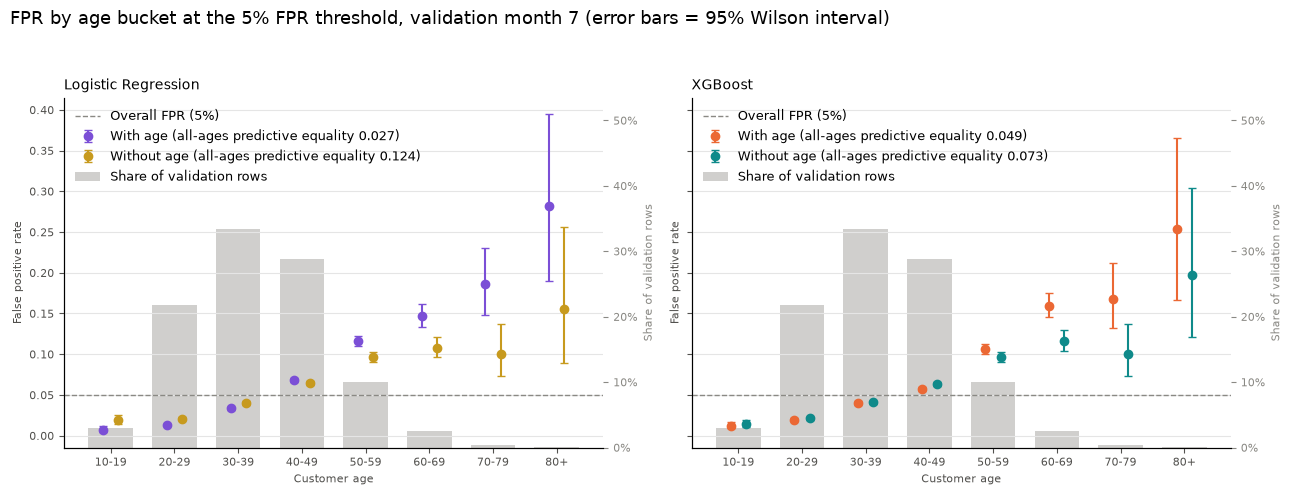

In [43]:
def wilson_interval(successes, n, z=1.96):
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half_width, centre + half_width


def plot_fpr_by_age(families):
    fig, axes = plot.subplots(1, len(families), figsize=(6.5 * len(families), 5), sharey=True)
    x = np.arange(len(AGE_BUCKET_LABELS))

    for ax, family in zip(np.atleast_1d(axes), families):
        # Share of all validation rows in each bucket, drawn on a second axis behind the FPR points
        share_ax = ax.twinx()
        share_ax.bar(x, age_population['Share of rows'], width=0.7, color=REFERENCE_COLOR, alpha=0.4,
                     label='Share of validation rows')
        share_ax.set_ylim(0, age_population['Share of rows'].max() * 1.6)
        share_ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
        share_ax.tick_params(labelsize=8, colors=REFERENCE_COLOR)
        share_ax.set_ylabel('Share of validation rows', fontsize=8, color=REFERENCE_COLOR)
        share_ax.spines[['top', 'right']].set_visible(False)
        ax.set_zorder(share_ax.get_zorder() + 1)
        ax.patch.set_visible(False)

        # With- and without-age points sit either side of each tick
        model_variants = [
            (-0.12, f'{family} (tuned)', 'With age'),
            (0.12, f'{family} (tuned, no age)', 'Without age'),
        ]
        for offset, name, label in model_variants:
            table = age_fpr_tables[name]
            low, high = wilson_interval(table['false_positives'], table['non_fraud'])
            error = [table['fpr'] - low, high - table['fpr']]
            equality = results.loc[name, 'Predictive equality (all ages)']
            ax.errorbar(x + offset, table['fpr'], yerr=error, fmt='o', color=MODEL_COLORS[name], markersize=6,
                        capsize=3, linewidth=1.5, label=f'{label} (all-ages predictive equality {equality:.3f})')

        ax.axhline(TARGET_FPR, linestyle='--', linewidth=1, color=REFERENCE_COLOR,
                   label=f'Overall FPR ({TARGET_FPR:.0%})')
        ax.set_xticks(x)
        ax.set_xticklabels(AGE_BUCKET_LABELS.values())
        style_axis(ax, family, 'False positive rate')
        ax.set_xlabel('Customer age', fontsize=8, color='#52514e')

        handles, labels = ax.get_legend_handles_labels()
        share_handles, share_labels = share_ax.get_legend_handles_labels()
        ax.legend(handles + share_handles, labels + share_labels, loc='upper left', frameon=False, fontsize=9)

    title = (f'FPR by age bucket at the {TARGET_FPR:.0%} FPR threshold, validation month 7 '
             '(error bars = 95% Wilson interval)')
    fig.suptitle(title, x=0.01, ha='left', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig


age_fpr_fig = plot_fpr_by_age(['Logistic Regression', 'XGBoost'])
plot.show()

In [44]:
with mlflow.start_run(run_name='Age removal fairness comparison'):
    mlflow.log_params({
        'dropped_features': AGE_COLS,
        'models': AGE_COMPARISON_MODELS,
        'age_bucket_cap': AGE_BUCKET_CAP,
        'target_fpr': TARGET_FPR,
        'val_months': val_months,
    })
    for family in ('Logistic Regression', 'XGBoost'):
        with_age = age_metric_comparison.loc[f'{family} (tuned)']
        without_age = age_metric_comparison.loc[f'{family} (tuned, no age)']
        change = without_age - with_age

        prefix = family.lower().replace(' ', '_')
        change_metrics = {f'{prefix}_{METRIC_NAMES[column]}_change': value for column, value in change.items()}
        mlflow.log_metrics(change_metrics)
    mlflow.log_text(age_metric_comparison.to_csv(), 'metrics_comparison.csv')
    mlflow.log_text(age_fpr_comparison.to_csv(), 'fpr_by_age_bucket.csv')
    mlflow.log_figure(age_fpr_fig, 'fpr_by_age_bucket.png')

🏃 View run Age removal fairness comparison at: http://localhost:5000/#/experiments/1/runs/25e76a1f67a84e9e882165457d7c2700
🧪 View experiment at: http://localhost:5000/#/experiments/1


## Explaining Individual Predictions (SHAP)

Four validation cases are picked for each tuned model, using that model's own 5% FPR threshold:
- **Highest-scoring true positive:** a clear-cut catch.
- **Borderline false positive:** the non-fraud applicant with the lowest score that still clears the threshold.
- **Lowest-scoring false negative:** the fraud the model was most confident wasn't fraud.
- **Highest-scoring false positive aged 50+:** the older legitimate applicant the model is most sure is fraud, to see case by case what drives the FPR gap.

Each model has its own threshold and its own mistakes, so the logistic regression and XGBoost plots for a case are usually different applicants.

SHAP values come from the `shap` package:
- **XGBoost:** `shap.TreeExplainer`, exact TreeSHAP over the trees `predict_proba` uses, including the native categorical splits.
- **Logistic regression:** `shap.LinearExplainer`, which treats features as independent, so a feature's SHAP value is its coefficient times (value - training mean). The background is the full training mean and covariance, since passing the training DataFrame would subsample it to 100 rows. One-hot columns are summed back into their source feature, so both models are explained on the same features. Feature values are shown before scaling.

Each plot is a `shap.plots.waterfall` in log-odds. It starts at the model's average output, E[f(X)], each feature pushes toward fraud (red) or non-fraud (blue), and it ends at the case's output, f(x). The dashed line is the decision threshold: a case is flagged when f(x) is to its right. A check confirms the SHAP values add back up to each case's score.

In [45]:
SHAP_MODELS = ['Logistic Regression (tuned)', 'XGBoost (tuned)']

# A DataFrame background is subsampled to 100 rows, so the full training mean and covariance are passed instead
lr_background = (X_train_lr.mean().to_numpy(), X_train_lr.cov().to_numpy())
lr_explainer = shap.LinearExplainer(lr_tuned, lr_background)
xgb_explainer = shap.TreeExplainer(xgb_tuned)


def lr_source_feature(col):
    # One-hot output columns map back to the feature they came from; every other column maps to itself
    for onehot_col in lr_onehot_cols:
        if col.startswith(f'{onehot_col}_'):
            return onehot_col
    return col


lr_feature_sources = {col: lr_source_feature(col) for col in X_train_lr.columns}


def format_feature_value(value):
    if isinstance(value, str):
        return value
    if pd.isna(value):
        return 'missing'
    return f'{value:,.0f}' if abs(value) >= 100 else f'{value:.3g}'


def explain_lr(positions):
    explanation = lr_explainer(X_val_lr.iloc[positions])

    # Sum the one-hot SHAP values back into their source feature, so both models are explained on the same features
    column_values = pd.DataFrame(explanation.values, columns=X_val_lr.columns)
    values = column_values.T.groupby(lr_feature_sources).sum().T
    return values, explanation.base_values, lr_val_input.iloc[positions][values.columns]


def explain_xgb(positions):
    explanation = xgb_explainer(X_val_xgb.iloc[positions])
    values = pd.DataFrame(explanation.values, columns=X_val_xgb.columns)
    return values, explanation.base_values, X_val_xgb.iloc[positions]


SHAP_EXPLAINERS = {'Logistic Regression (tuned)': explain_lr, 'XGBoost (tuned)': explain_xgb}


def pick_cases(scores, threshold):
    # Positions in the validation month of the four cases, using this model's own threshold
    flagged = scores >= threshold
    fraud = y_val_array == 1
    older = val_age >= AGE_GROUP_CUTOFF

    def pick(mask, highest):
        positions = np.flatnonzero(mask)
        if highest:
            return positions[np.argmax(scores[positions])]
        return positions[np.argmin(scores[positions])]

    return {
        'Highest-scoring true positive': pick(fraud & flagged, highest=True),
        'Borderline false positive': pick(~fraud & flagged, highest=False),
        'Lowest-scoring false negative': pick(fraud & ~flagged, highest=False),
        f'Highest-scoring false positive aged {AGE_GROUP_CUTOFF}+': pick(~fraud & flagged & older, highest=True),
    }


shap_cases = {}
for name in SHAP_MODELS:
    scores = val_scores[name]
    threshold = results.loc[name, 'Threshold']
    cases = pick_cases(scores, threshold)
    positions = list(cases.values())

    values, base_values, feature_values = SHAP_EXPLAINERS[name](positions)
    # SHAP values plus the base value add up to each case's log-odds, so they must reproduce its score
    reconstructed_scores = expit(base_values + values.sum(axis=1))
    np.testing.assert_allclose(reconstructed_scores, scores[positions], rtol=1e-3, atol=1e-6)

    shap_cases[name] = {}
    for i, (case, position) in enumerate(cases.items()):
        case_values = feature_values.iloc[i]
        explanation = shap.Explanation(
            values=values.iloc[i].to_numpy(),
            base_values=float(base_values[i]),
            data=case_values.to_numpy(),
            display_data=np.array([format_feature_value(value) for value in case_values]),
            feature_names=list(values.columns),
        )
        shap_cases[name][case] = {
            'position': position,
            'explanation': explanation,
            'score': scores[position],
            'threshold': threshold,
        }

summary_rows = []
for name, cases in shap_cases.items():
    for case, info in cases.items():
        position = info['position']
        summary_rows.append({
            'model': name,
            'case': case,
            'val_row': X_val.index[position],
            'customer_age': val_age[position],
            'fraud_bool': y_val_array[position],
            'score': info['score'],
            'threshold': info['threshold'],
        })

shap_case_summary = pd.DataFrame(summary_rows).set_index(['case', 'model'])
shap_case_summary = shap_case_summary.sort_index(level='case', sort_remaining=False)
shap_case_summary.round(4)

val_row  \
case                                    model                                  
Borderline false positive               Logistic Regression (tuned)   968285   
                                        XGBoost (tuned)               954531   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)   953167   
                                        XGBoost (tuned)               907882   
Highest-scoring true positive           Logistic Regression (tuned)   945854   
                                        XGBoost (tuned)               938291   
Lowest-scoring false negative           Logistic Regression (tuned)   962445   
                                        XGBoost (tuned)               981016   

                                                                     customer_age  \
case                                    model                                       
Borderline false positive               Logistic Regression (tuned)            20   
                                        XGBoost (tuned)                        40   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)            60   
                                        XGBoost (tuned)                        60   
Highest-scoring true positive           Logistic Regression (tuned)            70   
                                        XGBoost (tuned)                        30   
Lowest-scoring false negative           Logistic Regression (tuned)            50   
                                        XGBoost (tuned)                        30   

                                                                     fraud_bool  \
case                                    model                                     
Borderline false positive               Logistic Regression (tuned)           0   
                                        XGBoost (tuned)                       0   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)           0   
                                        XGBoost (tuned)                       0   
Highest-scoring true positive           Logistic Regression (tuned)           1   
                                        XGBoost (tuned)                       1   
Lowest-scoring false negative           Logistic Regression (tuned)           1   
                                        XGBoost (tuned)                       1   

                                                                      score  \
case                                    model                                 
Borderline false positive               Logistic Regression (tuned)  0.0329   
                                        XGBoost (tuned)              0.0672   
Highest-scoring false positive aged 50+ Logistic Regression (tuned)  0.4942   
                                        XGBoost (tuned)              0.8217   
Highest-scoring true positive           Logistic Regression (tuned)  0.7689   
                                        XGBoost (tuned)              0.9404   
Lowest-scoring false negative           Logistic Regression (tuned)  0.0002   
                                        XGBoost (tuned)              0.0004   

                                                                     threshold  
case                                    model                                   
Borderline false positive               Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)                 0.0672  
Highest-scoring false positive aged 50+ Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)                 0.0672  
Highest-scoring true positive           Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)                 0.0672  
Lowest-scoring false negative           Logistic Regression (tuned)     0.0329  
                                        XGBoost (tuned)           

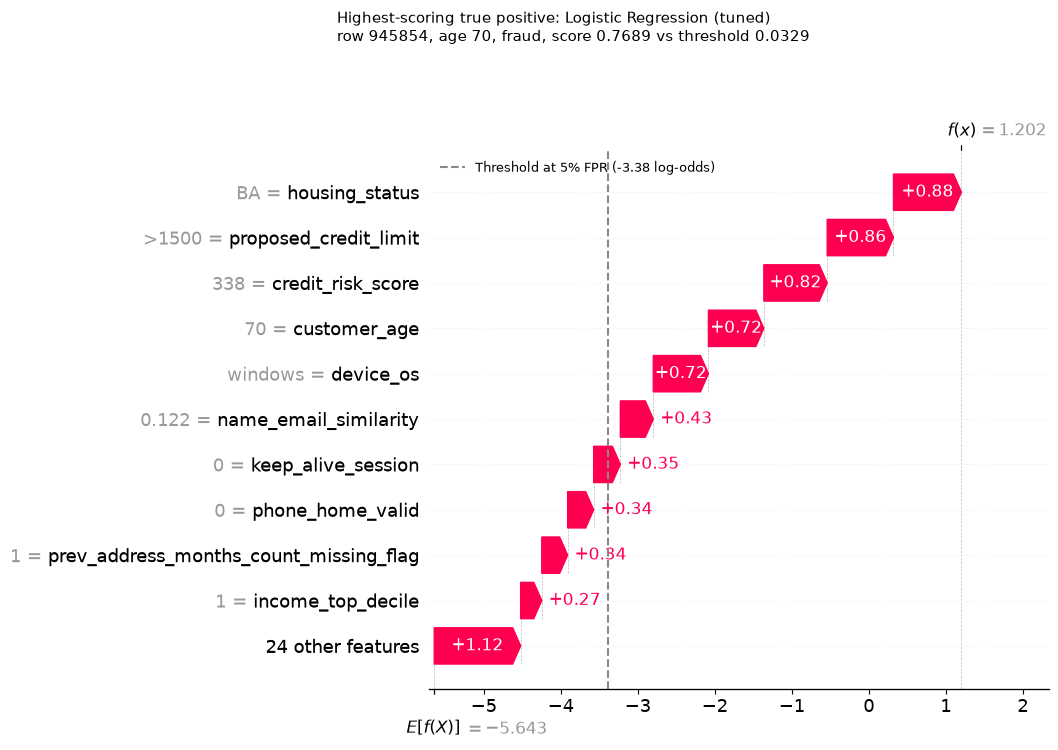

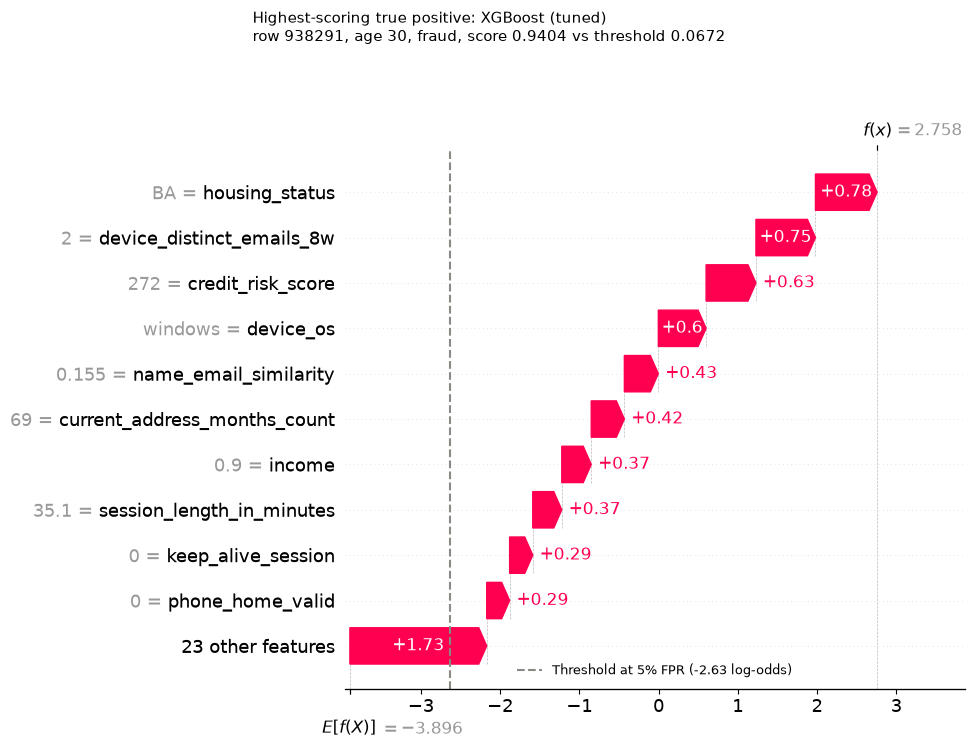

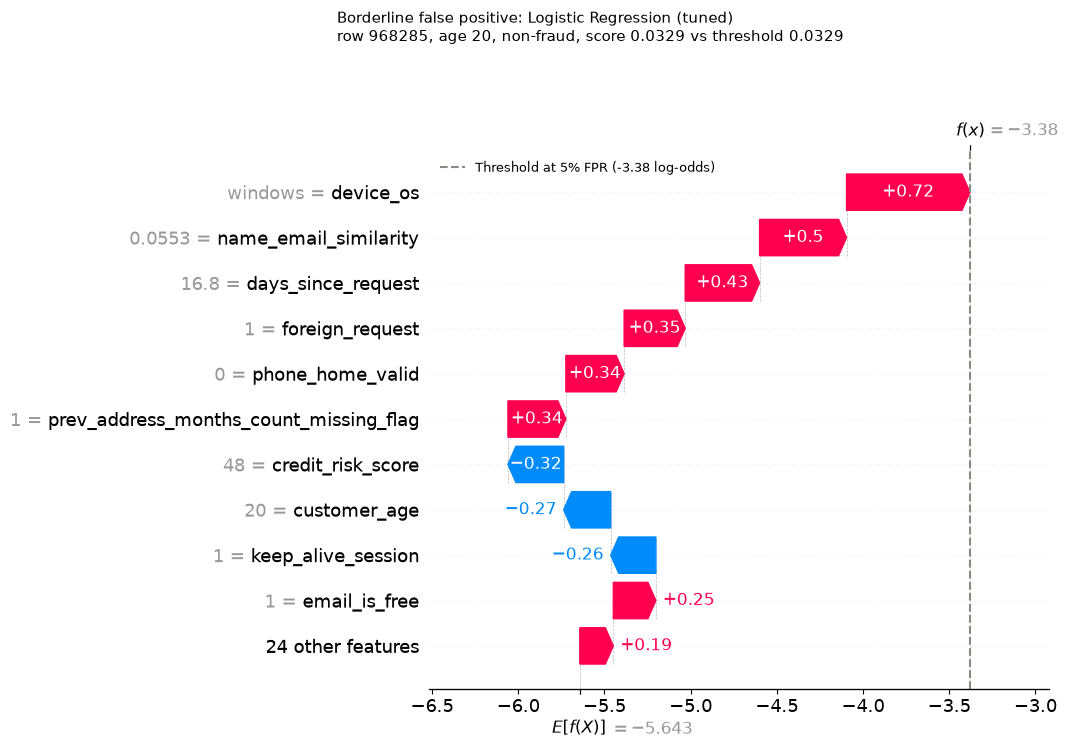

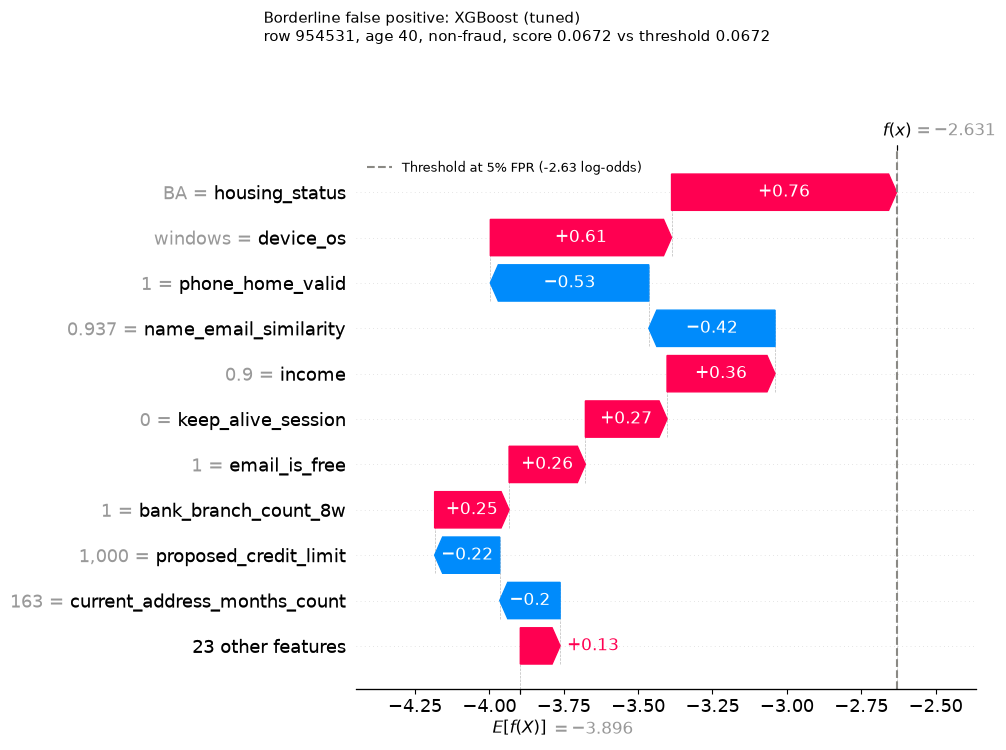

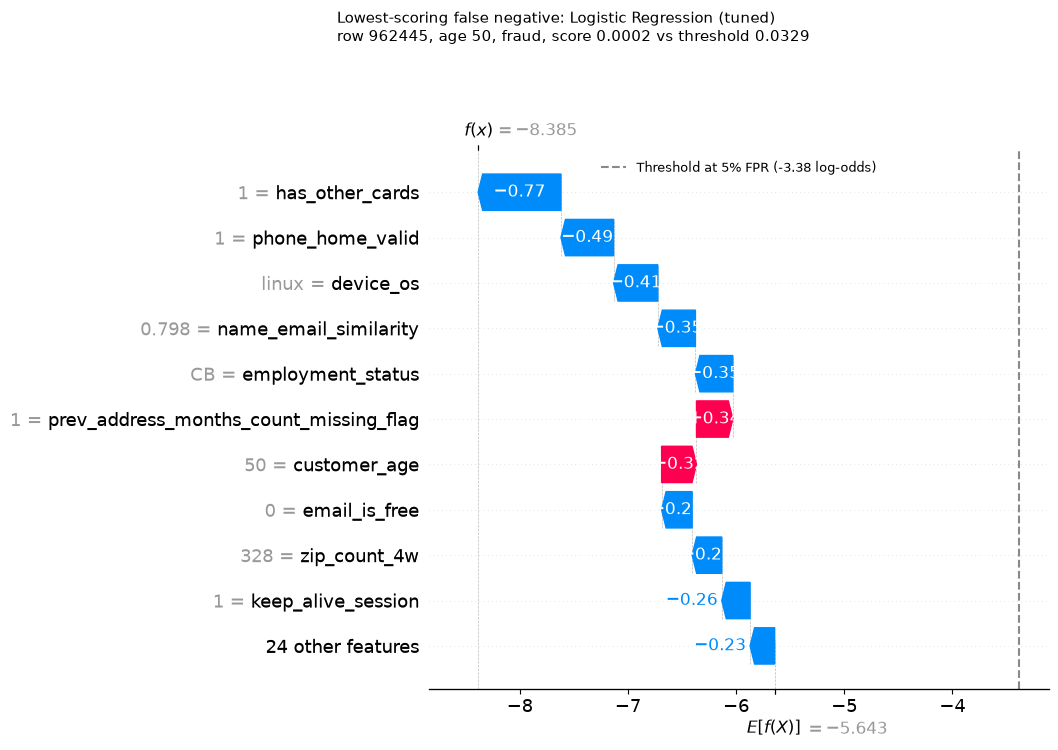

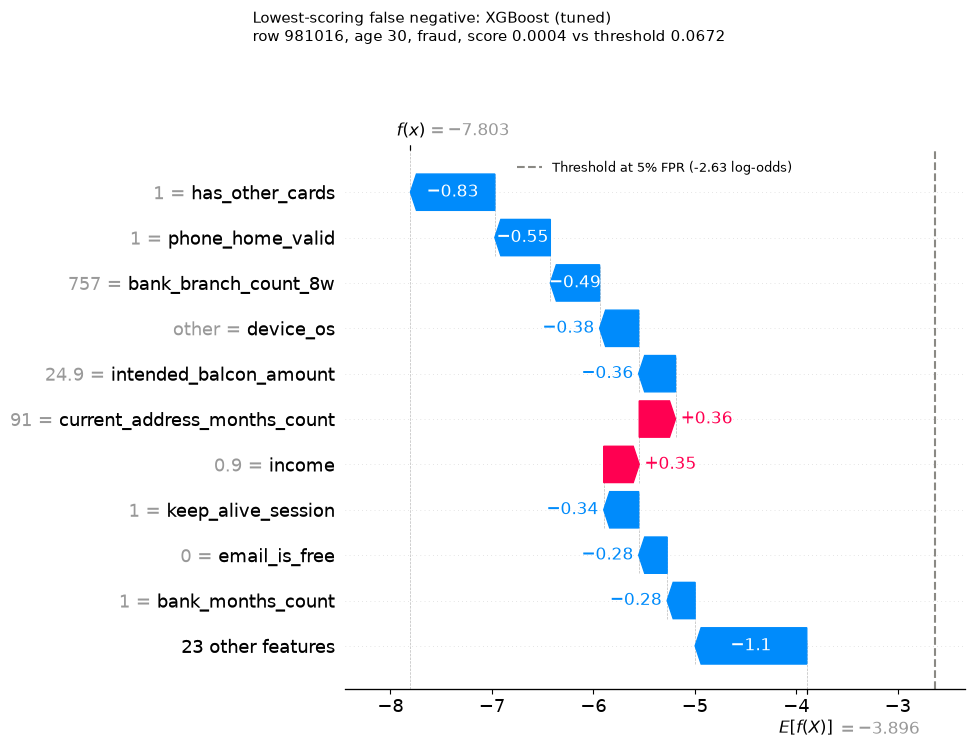

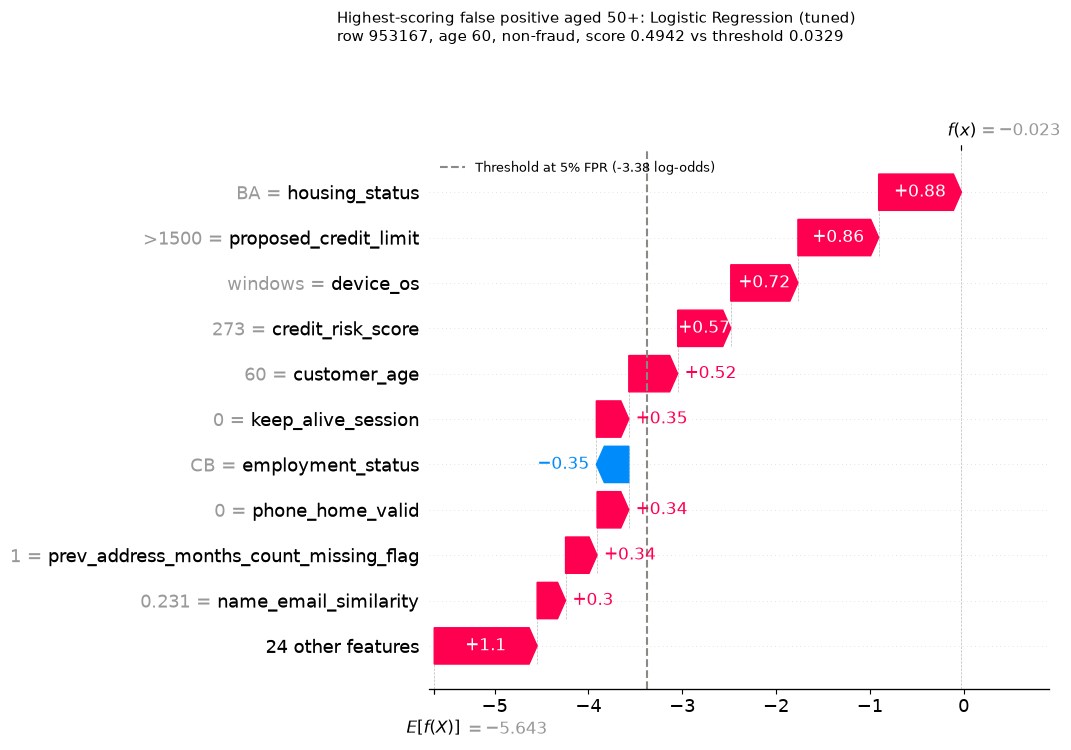

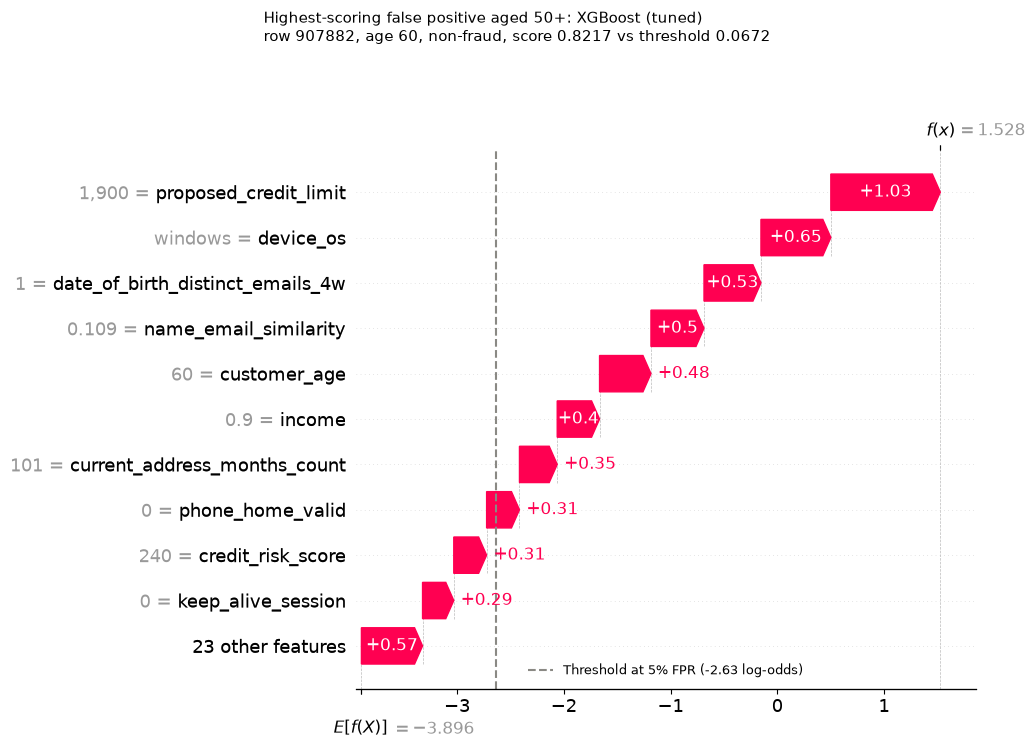

In [46]:
SHAP_MAX_DISPLAY = 11  # the 10 largest contributions, plus one bar summing the rest


def add_threshold_line(fig, threshold):
    # Widen every axis together so the threshold is in view: waterfall's E[f(X)] and f(x) labels sit on twin axes
    # that only stay aligned with the bars if all of them share the same limits
    ax = fig.axes[0]
    threshold_log_odds = logit(threshold)

    lo, hi = ax.get_xlim()
    pad = 0.05 * (max(hi, threshold_log_odds) - min(lo, threshold_log_odds))
    new_lo = min(lo, threshold_log_odds - pad)
    new_hi = max(hi, threshold_log_odds + pad)
    for axis in fig.axes:
        axis.set_xlim(new_lo, new_hi)

    label = f'Threshold at {TARGET_FPR:.0%} FPR ({threshold_log_odds:.2f} log-odds)'
    line = ax.axvline(threshold_log_odds, color=REFERENCE_COLOR, linewidth=1.5, linestyle='--', label=label)
    ax.legend(handles=[line], loc='best', frameon=False, fontsize=9)


# shap.plots.waterfall draws on the current figure and has no ax argument, so each model gets its own figure
for case in shap_cases[SHAP_MODELS[0]]:
    for name in SHAP_MODELS:
        info = shap_cases[name][case]
        position = info['position']
        outcome = 'fraud' if y_val_array[position] else 'non-fraud'
        title = (f"{case}: {name}\n"
                 f"row {X_val.index[position]}, age {val_age[position]}, {outcome}, "
                 f"score {info['score']:.4f} vs threshold {info['threshold']:.4f}")

        fig = plot.figure()
        shap.plots.waterfall(info['explanation'], max_display=SHAP_MAX_DISPLAY, show=False)
        add_threshold_line(fig, info['threshold'])
        fig.suptitle(title, x=0.01, ha='left', y=1.08, fontsize=11)
        plot.show()